# 🍎 MobileViT vs CNN tự xây — Nhận dạng trái cây (Fruits-360)

**Đồ án môn học — Nhóm 17 — Trần Duy Đang (106220126)**
Đề tài: *Fruit classification* — hướng tiếp cận: **MobileViT + CNN tự xây dựng**.

Notebook này làm 3 việc:
1. **Giải thích thuật toán**: CNN học gì, Transformer học gì, và MobileViT ghép 2 thứ đó lại như thế nào.
2. **Cài đặt MobileViT từ đầu** (không dùng thư viện có sẵn) và **huấn luyện cả 2 mô hình bằng cùng một công thức** để so sánh công bằng.
3. **So sánh toàn diện**, không chỉ nhìn accuracy (vì trên Fruits-360 cả 2 đều gần 100%):
   độ chính xác & F1, số tham số, dung lượng, số phép tính, tốc độ, khả năng học khi **ít dữ liệu**, độ bền khi ảnh bị **nhiễu / đổi nền**, ảnh **ngoài đời thật**, và **Grad-CAM** (mô hình nhìn vào đâu).

## Mục lục
0. Chuẩn bị & cấu hình
1. Dữ liệu (dùng lại bộ 15 lớp đã tạo ở notebook trước)
2. Lý thuyết: CNN → Vision Transformer → MobileViT
3. Cài đặt 2 mô hình
4. Huấn luyện (cùng công thức)
5. Đánh giá trên tập Test
6. Hiệu năng: tham số, dung lượng, FLOPs, tốc độ
7. Thí nghiệm A — Khi chỉ có ít dữ liệu
8. Thí nghiệm B — Độ bền: nhiễu, mờ, xoay, che, **đổi nền**
9. Thí nghiệm C — Ảnh thật ngoài dataset
10. Grad-CAM — mô hình nhìn vào đâu?
11. Tổng kết & nhận xét tự động

> ⏱️ Thời gian chạy toàn bộ ước tính **khoảng 20–40 phút trên RTX 3060** (phần lớn là huấn luyện MobileViT và thí nghiệm ít dữ liệu). Có thể tắt thí nghiệm A ở ô cấu hình nếu cần nhanh.

## 0. Chuẩn bị & cấu hình

**Yêu cầu trước khi chạy:** đã chạy notebook `Fruit_CNN_Classification.ipynb` tới bước tạo bộ dữ liệu con, tức là đã có thư mục `~/fruit-cnn-project/fruits_subset/Training` và `.../Test` (15 loại trái cây). Notebook này **dùng lại đúng bộ dữ liệu đó**, nên kết quả 2 notebook có thể đặt cạnh nhau.

Mở notebook trong VS Code (đã kết nối WSL) và chọn kernel `venv` của project như notebook trước.

In [2]:
import os, time, json, gc, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import tensorflow as tf
import keras
from keras import layers, ops
from PIL import Image
from scipy import ndimage, stats
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=UserWarning)
tf.get_logger().setLevel("ERROR")   # ẩn bớt cảnh báo không quan trọng của TensorFlow
gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    try:
        tf.config.experimental.set_memory_growth(g, True)
    except RuntimeError:
        pass
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPU:", [g.name for g in gpus] if gpus else "KHÔNG có GPU — vẫn chạy được nhưng chậm hơn nhiều")

I0000 00:00:1791903627.492740     808 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791903628.354345     808 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791903629.902082     808 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.22.0-rc0 | Keras 3.16.0.dev2026092804
GPU: ['/physical_device:GPU:0']


In [3]:
# ======================= CẤU HÌNH =======================
BASE_DIR    = os.path.expanduser("~/fruit-cnn-project")
DATA_TRAIN  = os.path.join(BASE_DIR, "fruits_subset", "Training")
DATA_TEST   = os.path.join(BASE_DIR, "fruits_subset", "Test")
MODEL_DIR   = os.path.join(BASE_DIR, "model")
RESULTS_DIR = os.path.join(BASE_DIR, "results")          # mọi hình + số liệu được lưu ở đây (dùng làm slide)
EXTERNAL_DIR = os.path.join(BASE_DIR, "external_test")   # ảnh thật bạn tự sưu tầm (Thí nghiệm C)

IMG_SIZE    = (128, 128)   # CẢ 2 mô hình dùng chung kích thước ảnh (MobileViT cần chia hết cho 32)
BATCH_SIZE  = 32
SEED        = 42
VAL_FRACTION = 0.2         # 20% ảnh Training dùng làm validation

# Công thức huấn luyện — GIỐNG HỆT NHAU cho 2 mô hình
EPOCHS        = 30
PATIENCE      = 6          # dừng sớm nếu val_loss không giảm sau 6 epoch...
MIN_EPOCHS    = 10         # ...nhưng luôn train ít nhất 10 epoch (MobileViT thường dao động mạnh ở vài epoch đầu)
LEARNING_RATE = 1e-3
WEIGHT_DECAY  = 1e-2
WARMUP_EPOCHS = 2

MOBILEVIT_VARIANT = "xxs"  # "xxs" (~1M tham số), "xs" (~2M), "s" (~5M)

# Thí nghiệm A: học với bao nhiêu % dữ liệu train
RUN_DATA_EFFICIENCY = True
DATA_FRACTIONS = [0.02, 0.05, 0.10, 0.25]   # 100% lấy luôn từ lần huấn luyện chính
N_REPEATS = 1                               # tăng lên 3 nếu có thời gian -> có thêm độ lệch chuẩn

LATENCY_RUNS = 50          # số lần đo tốc độ
# =========================================================

AUTOTUNE = tf.data.AUTOTUNE
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
keras.utils.set_random_seed(SEED)

def savefig(name):
    path = os.path.join(RESULTS_DIR, name)
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print("Đã lưu hình:", path)

## 1. Dữ liệu

Ta đọc lại 15 loại trái cây trong `fruits_subset`, rồi:
- Tách **20% ảnh Training làm validation**, tách **phân tầng (stratified)** để mỗi loại đều có đủ tỷ lệ.
- Tập **Test** giữ nguyên (do tác giả Fruits-360 chụp riêng) — đây là thước đo chính.
- Resize về **128×128** cho cả 2 mô hình.

> 🔧 **Sửa 1 lỗi nhỏ so với notebook trước:** trước đây pipeline gọi `augmentation` **rồi mới** `.cache()` → ảnh chỉ được biến đổi ngẫu nhiên **1 lần** rồi bị lưu cứng, các epoch sau dùng lại y hệt (augmentation gần như vô tác dụng). Ở đây đổi thứ tự: **cache ảnh gốc trước, augment sau** → mỗi epoch ảnh được xoay/lật/zoom khác nhau.

> ⚠️ **Lưu ý khi đọc kết quả validation:** Fruits-360 được tạo bằng cách quay video quả trái cây xoay trên trục rồi cắt từng khung hình. Hai khung hình liền nhau gần như giống hệt, nên khi tách ngẫu nhiên Training → train/val thì val **rất giống** train ⇒ val accuracy ≈ 100% ngay từ epoch đầu. Vì vậy **mọi kết luận đều dựa trên tập Test** (và các thí nghiệm B, C), không dựa trên val.

In [4]:
IMG_EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

def list_images(root, class_names=None):
    if class_names is None:
        class_names = sorted(d for d in os.listdir(root) if os.path.isdir(os.path.join(root, d)))
    paths, labels = [], []
    for i, c in enumerate(class_names):
        folder = os.path.join(root, c)
        for f in sorted(os.listdir(folder)):
            if f.lower().endswith(IMG_EXTS):
                paths.append(os.path.join(folder, f))
                labels.append(i)
    return np.array(paths), np.array(labels, dtype="int32"), class_names

assert os.path.isdir(DATA_TRAIN) and os.path.isdir(DATA_TEST), (
    f"Không thấy {DATA_TRAIN}. Hãy chạy notebook Fruit_CNN_Classification.ipynb tới bước tạo fruits_subset trước.")

all_train_paths, all_train_labels, class_names = list_images(DATA_TRAIN)
test_paths, test_labels, _ = list_images(DATA_TEST, class_names)
num_classes = len(class_names)

train_paths, val_paths, train_labels, val_labels = train_test_split(
    all_train_paths, all_train_labels, test_size=VAL_FRACTION,
    stratify=all_train_labels, random_state=SEED)

counts = pd.DataFrame({
    "Train": np.bincount(train_labels, minlength=num_classes),
    "Val":   np.bincount(val_labels, minlength=num_classes),
    "Test":  np.bincount(test_labels, minlength=num_classes),
}, index=class_names)
counts.loc["TỔNG"] = counts.sum()
print(f"{num_classes} lớp:", class_names)
display(counts)

15 lớp: ['Apple Pink Lady', 'Apple Red', 'Apple Red Delicious', 'Cabbage white', 'Cactus fruit', 'Caju seed', 'Carambola', 'Cherry Sour', 'Grape Blue', 'Grape White', 'Grapefruit White', 'Huckleberry', 'Lychee', 'Physalis', 'Zucchini']


,Train,Val,Test
Apple Pink Lady,365,91,152
Apple Red,1130,283,472
Apple Red Delicious,392,98,166
Cabbage white,115,29,47
Cactus fruit,392,98,166
Caju seed,181,45,75
Carambola,1538,385,642
Cherry Sour,365,91,150
Grape Blue,787,197,328
Grape White,1554,389,654


In [5]:
def load_image(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(tf.clip_by_value(tf.round(img), 0, 255), tf.uint8)  # cache dạng uint8 cho nhẹ RAM
    return img, label

# Augmentation nhẹ (giống notebook trước): lật ngang, xoay ±10% vòng (±36°), zoom ±10%
augmenter = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="augmentation")

def make_dataset(paths, labels, training=False, batch_size=BATCH_SIZE):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).cache()          # 1) cache ảnh GỐC
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(batch_size)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    if training:                                                          # 2) augment SAU cache -> mỗi epoch khác nhau
        ds = ds.map(lambda x, y: (augmenter(x, training=True), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_dataset(train_paths, train_labels, training=True)
val_ds   = make_dataset(val_paths, val_labels)
test_ds  = make_dataset(test_paths, test_labels)
print("Số batch — train:", int(train_ds.cardinality()), "| val:", int(val_ds.cardinality()),
      "| test:", int(test_ds.cardinality()))

I0000 00:00:1791903715.016048     808 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9711 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:01:00.0, compute capability: 8.6


Số batch — train: 269 | val: 68 | test: 113


Đã lưu hình: /home/tranduydang/fruit-cnn-project/results/01_classes.png


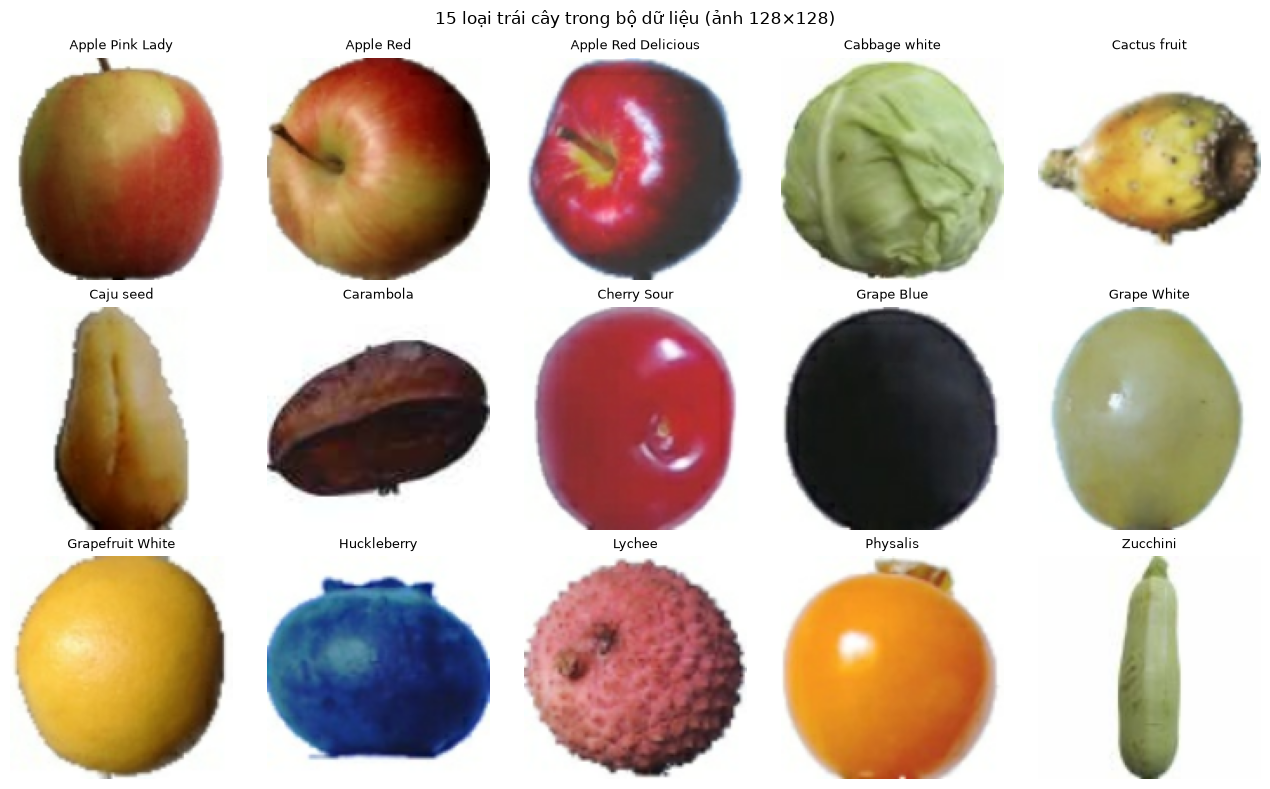

W0000 00:00:1791861037.416283   56520 local_rendezvous.cc:461] Local rendezvous is aborting with status: CANCELLED: RecvAsync is cancelled.
	 [[{{node GroupCrossDeviceControlEdges_0/NoOp/_21}}]] [type.googleapis.com/tensorflow.DerivedStatus='']
=== Source Location Trace: ===
tensorflow/core/framework/local_rendezvous.cc:339
tensorflow/core/common_runtime/executor.cc:1156

W0000 00:00:1791861037.416452   56520 local_rendezvous.cc:461] Local rendezvous is aborting with status: CANCELLED: RecvAsync is cancelled.
	 [[{{node GroupCrossDeviceControlEdges_0/NoOp/_21}}]] [type.googleapis.com/tensorflow.DerivedStatus='']
=== Source Location Trace: ===
tensorflow/core/framework/local_rendezvous.cc:339
tensorflow/core/common_runtime/executor.cc:1156

W0000 00:00:1791861037.423840   56773 local_rendezvous.cc:461] Local rendezvous is aborting with status: CANCELLED: RecvAsync is cancelled.
	 [[{{node augmentation_1/random_zoom/Add/_14}}]] [type.googleapis.com/tensorflow.DerivedStatus='']
=== Source

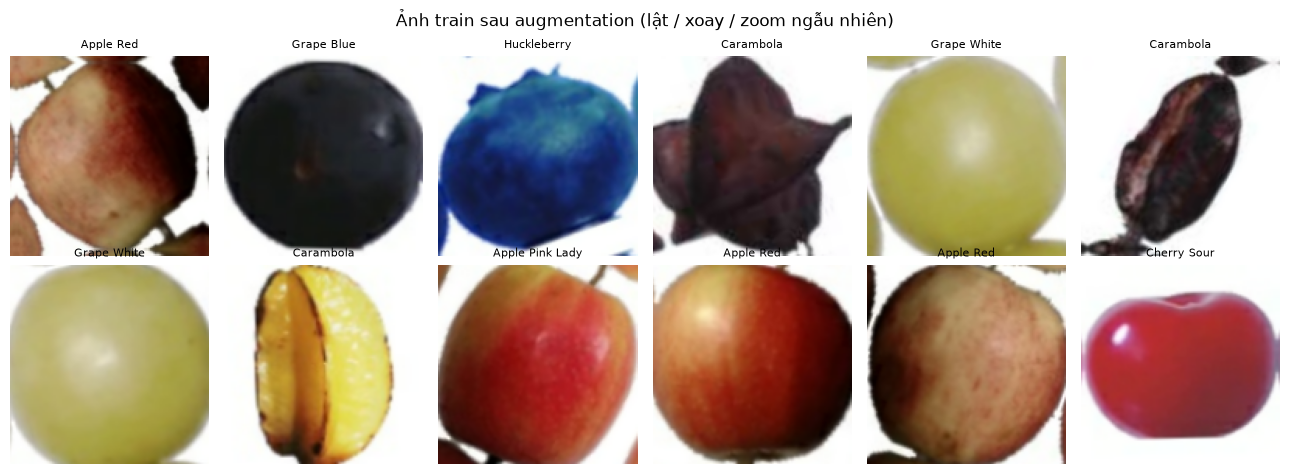

In [5]:
# Xem thử 1 ảnh của mỗi loại + 1 batch sau augmentation
fig, axes = plt.subplots(3, 5, figsize=(13, 8))
for ax, i in zip(axes.flat, range(num_classes)):
    p = train_paths[np.where(train_labels == i)[0][0]]
    ax.imshow(load_image(p, 0)[0].numpy()); ax.set_title(class_names[i], fontsize=9); ax.axis("off")
plt.suptitle("15 loại trái cây trong bộ dữ liệu (ảnh 128×128)")
plt.tight_layout(); savefig("01_classes.png"); plt.show()

xb, yb = next(iter(train_ds))
fig, axes = plt.subplots(2, 6, figsize=(13, 4.8))
for ax, img, lab in zip(axes.flat, xb.numpy(), yb.numpy()):
    ax.imshow(img.astype("uint8")); ax.set_title(class_names[lab], fontsize=8); ax.axis("off")
plt.suptitle("Ảnh train sau augmentation (lật / xoay / zoom ngẫu nhiên)")
plt.tight_layout(); plt.show()

## 2. Lý thuyết: CNN → Vision Transformer → MobileViT

### 2.1. CNN tự xây làm gì? (nhắc lại bài giảng — AlexNet/VGG)
- **Convolution 3×3**: một bộ lọc nhỏ trượt khắp ảnh → phát hiện đặc trưng **cục bộ** (cạnh, màu, vân). Cùng một bộ lọc dùng cho mọi vị trí (*chia sẻ trọng số*).
- Xếp chồng **Conv → ReLU → MaxPool** → đặc trưng từ **thấp** (cạnh) → **trung** (đường cong, kết cấu) → **cao** (hình dáng quả).
- Cuối mạng: **Flatten + Dense** để phân loại.

**Hai điểm yếu** (đúng như slide *"VGG and AlexNet are inefficient"*):
1. **Tầm nhìn (receptive field) tăng chậm**: mỗi lớp 3×3 chỉ "nhìn" thêm 1 pixel mỗi phía. Muốn 1 nơ-ron thấy được *cả quả* thì cần rất nhiều lớp/pooling. ⇒ CNN giỏi chi tiết cục bộ, **yếu về ngữ cảnh toàn cục**.
2. **Lớp Dense sau Flatten rất tốn tham số**: trong CNN của mình, `Flatten` ra 14×14×128 = 25.088 số, nối với Dense 128 ⇒ **≈ 3,2 triệu tham số — chiếm ~97% cả mạng** (sẽ thấy ở mục 3).

### 2.2. Vision Transformer (ViT) làm gì?
- Cắt ảnh thành các **patch** (ví dụ 16×16), mỗi patch thành 1 vector (*token*).
- **Self-attention**: mỗi token tính mức độ liên quan với **mọi token khác** rồi tổng hợp thông tin:
  $$\text{Attention}(Q,K,V)=\text{softmax}\left(\frac{QK^\top}{\sqrt{d}}\right)V$$
  ⇒ ngay từ lớp đầu tiên đã **nhìn toàn bộ ảnh** (toàn cục).
- **Nhược điểm:** ViT không có sẵn "kiến thức" về tính cục bộ như convolution (*thiếu inductive bias*) ⇒ cần **rất nhiều dữ liệu** (hàng chục–hàng trăm triệu ảnh) và nhiều tính toán; chi phí attention tăng theo **bình phương** số token. Không hợp với điện thoại hay dataset nhỏ.

### 2.3. MobileViT = CNN + Transformer (Mehta & Rastegari, Apple — ICLR 2022)
Ý tưởng: **"Transformer đóng vai trò như một phép convolution"** — giữ convolution để học đặc trưng cục bộ, chèn Transformer vào giữa để học quan hệ toàn cục, và **không làm mất cấu trúc không gian** của ảnh.

**Kiến trúc tổng thể** (ảnh 128×128):

| Tầng | Thành phần | Kích thước ra |
|---|---|---|
| Stem | Conv 3×3, stride 2 | 64×64×16 |
| Layer 1 | 1 khối MV2 | 64×64×16 |
| Layer 2 | 3 khối MV2 (khối đầu stride 2) | 32×32×24 |
| Layer 3 | MV2 (stride 2) + **MobileViT block** (L=2) | 16×16×48 |
| Layer 4 | MV2 (stride 2) + **MobileViT block** (L=4) | 8×8×64 |
| Layer 5 | MV2 (stride 2) + **MobileViT block** (L=3) | 4×4×80 |
| Head | Conv 1×1 → **Global Average Pooling** → Dense | 15 lớp |

*(số kênh là của phiên bản XXS; L = số lớp Transformer)*

**Khối MV2 (MobileNetV2 inverted residual)** — gồm toàn những ý tưởng có trong bài giảng:
`Conv 1×1 mở rộng kênh` → `Depthwise Conv 3×3` → `Conv 1×1 thu hẹp` (+ `residual` nếu cùng kích thước)
- Conv 1×1 = ý tưởng **Network-in-Network**.
- Depthwise conv = **grouped convolution** với số nhóm = số kênh (slide Grouped convolutions / ResNeXt): mỗi kênh có 1 bộ lọc 3×3 riêng. Cặp *depthwise 3×3 + conv 1×1* rẻ hơn một conv 3×3 thường khoảng 8–9 lần (theo paper MobileNet).
- Residual = **ResNet**.
- Cuối mạng dùng **Global Average Pooling** thay cho Flatten + Dense khổng lồ (lại là ý tưởng NiN) ⇒ rất ít tham số.

**Khối MobileViT** (trái tim của mô hình) — input `H×W×C`:
1. **Local representation:** Conv 3×3 (học đặc trưng cục bộ) → Conv 1×1 chiếu lên `d` chiều.
2. **Unfold:** chia feature map thành các patch 2×2 (P = 4 pixel/patch, N = HW/4 patch). Xếp lại thành **P chuỗi, mỗi chuỗi N token**: chuỗi thứ *p* gồm các pixel ở **cùng vị trí *p*** trong mọi patch.
3. **Global representation:** đưa từng chuỗi qua **L lớp Transformer** ⇒ mỗi pixel trao đổi thông tin với pixel cùng vị trí ở **tất cả các patch khác** (toàn ảnh).
4. **Fold:** ghép ngược về `H×W×d` — **giữ nguyên thứ tự patch và vị trí pixel** (khác ViT: ViT làm phẳng patch nên mất thứ tự không gian và phải thêm positional embedding).
5. **Fusion:** Conv 1×1 về `C` kênh → **nối (concat) với input ban đầu** → Conv 3×3 trộn local + global.

**Vì sao mỗi pixel "thấy" được cả ảnh?** Ở bước 1, mỗi pixel đã gom thông tin từ vùng 3×3 quanh nó (gồm cả các pixel khác vị trí trong patch). Ở bước 3, nó trao đổi với các pixel cùng vị trí ở mọi patch. Ghép 2 bước ⇒ **receptive field = toàn bộ H×W**.

**Vì sao rẻ hơn self-attention trên từng pixel?** Ở feature map 16×16 (256 pixel):
- Attention trên mọi pixel: 256 × 256 = **65.536** cặp.
- MobileViT: 4 chuỗi × (64 × 64) = **16.384** cặp ⇒ **ít hơn 4 lần** (= P).

**3 phiên bản trong paper** (ImageNet, ảnh 256×256): MobileViT-XXS 1,3M tham số — top-1 69,0%; XS 2,3M — 74,8%; S 5,6M — 78,4%. Ở đây dùng **XXS**.

### 2.4. So sánh trên lý thuyết
| Tiêu chí | CNN tự xây | MobileViT |
|---|---|---|
| Phép toán chính | Conv 3×3 + MaxPool + Dense | Conv (MV2, depthwise) + Transformer |
| Tầm nhìn | Cục bộ, tăng dần theo độ sâu | Cục bộ **+ toàn cục** ngay giữa mạng |
| "Kiến thức có sẵn" (inductive bias) | Mạnh (cục bộ, bất biến tịnh tiến) | Vẫn giữ nhờ conv, thêm attention linh hoạt |
| Đầu phân loại | Flatten + Dense (rất nhiều tham số) | Global Average Pooling (rất ít) |
| Kích hoạt / chuẩn hoá | ReLU, không BatchNorm | Swish, BatchNorm, LayerNorm |
| Độ phức tạp cài đặt | Đơn giản | Phức tạp hơn nhiều |

**Giả thuyết trước khi chạy** (sẽ kiểm chứng ở các mục sau):
- **H1.** Trên tập Test sạch, cả 2 đều rất cao (Fruits-360 dễ) — khó phân thắng thua chỉ bằng accuracy.
- **H2.** MobileViT có **ít tham số hơn nhiều** và **ít phép tính hơn**.
- **H3.** Dù ít phép tính, MobileViT **chưa chắc chạy nhanh hơn** trên GPU vì Transformer gồm nhiều phép nhỏ, reshape/transpose (chính paper cũng thừa nhận MobileViT chậm hơn MobileNet trên điện thoại).
- **H4.** Khi ảnh bị thay đổi (nhiễu, **đổi nền**...) hoặc ít dữ liệu, mô hình nào bền hơn là câu hỏi mở → đo bằng thí nghiệm A, B, C.

Đã lưu hình: /home/tranduydang/fruit-cnn-project/results/02_mobilevit_block.png


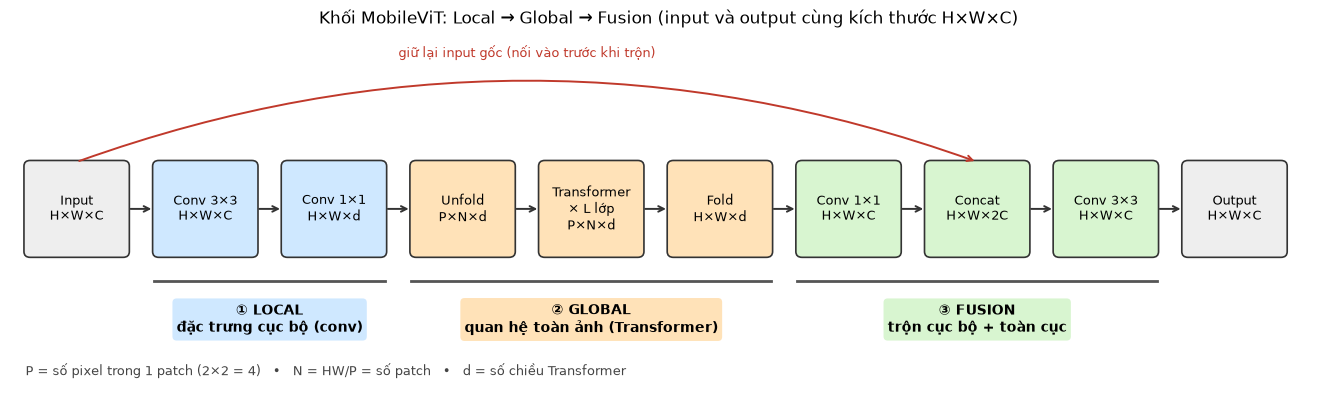

Đã lưu hình: /home/tranduydang/fruit-cnn-project/results/03_unfold.png


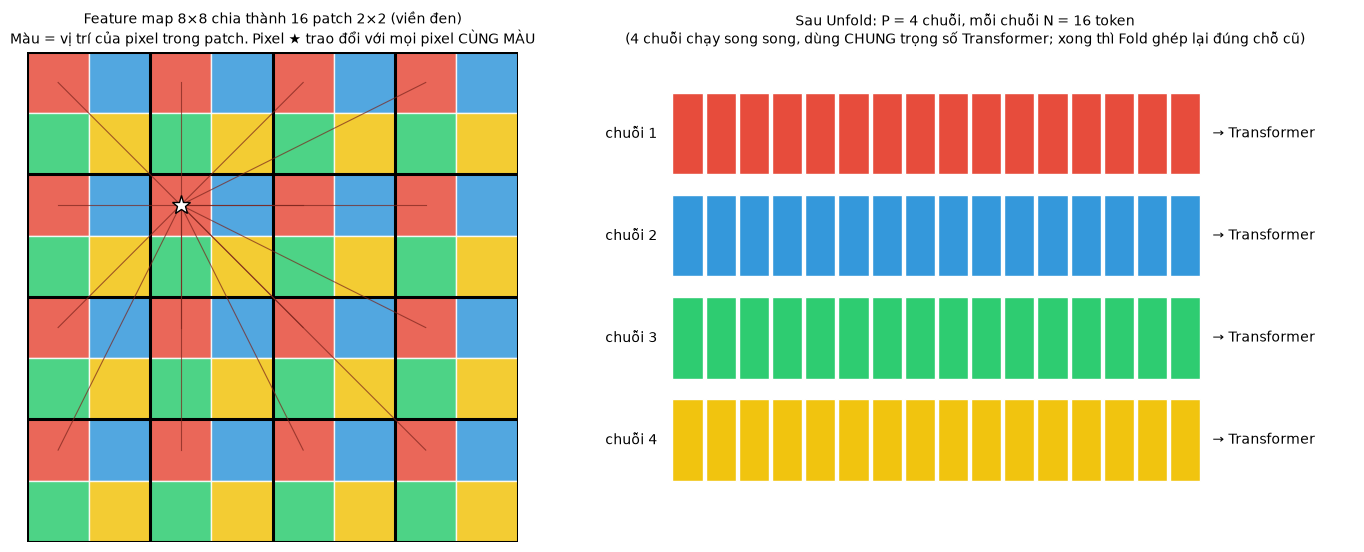

In [6]:
# Hình minh hoạ (dùng làm slide): (1) luồng dữ liệu trong khối MobileViT, (2) phép Unfold
def _box(ax, x, y, w, h, text, color, fontsize=9):
    ax.add_patch(mpatches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                         fc=color, ec="#333333", lw=1.2))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fontsize)

def _arrow(ax, x0, y0, x1, y1, **kw):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle="->", lw=1.4, color=kw.get("color", "#333333"),
                                connectionstyle=kw.get("cs", "arc3")))

# ---------- Hình 1: khối MobileViT ----------
fig, ax = plt.subplots(figsize=(17, 4.6))
ax.set_xlim(0, 17); ax.set_ylim(-0.3, 4.6); ax.axis("off")
C_LOCAL, C_GLOBAL, C_FUSE, C_IO = "#cfe8ff", "#ffe2b8", "#d8f5d0", "#eeeeee"
steps = [
    ("Input\nH×W×C", C_IO), ("Conv 3×3\nH×W×C", C_LOCAL), ("Conv 1×1\nH×W×d", C_LOCAL),
    ("Unfold\nP×N×d", C_GLOBAL), ("Transformer\n× L lớp\nP×N×d", C_GLOBAL), ("Fold\nH×W×d", C_GLOBAL),
    ("Conv 1×1\nH×W×C", C_FUSE), ("Concat\nH×W×2C", C_FUSE), ("Conv 3×3\nH×W×C", C_FUSE), ("Output\nH×W×C", C_IO),
]
bw, bh, gap, y0 = 1.32, 1.3, 0.34, 1.5
xs = [0.2 + i * (bw + gap) for i in range(len(steps))]
for (t, c), x in zip(steps, xs):
    _box(ax, x, y0, bw, bh, t, c)
for i in range(len(steps) - 1):
    _arrow(ax, xs[i] + bw, y0 + bh / 2, xs[i + 1], y0 + bh / 2)
# đường tắt: input -> concat
_arrow(ax, xs[0] + bw / 2, y0 + bh, xs[7] + bw / 2, y0 + bh, cs="arc3,rad=-0.18", color="#c0392b")
ax.text((xs[0] + xs[7]) / 2 + bw / 2, 4.25, "giữ lại input gốc (nối vào trước khi trộn)",
        ha="center", color="#c0392b", fontsize=9)
for (a, b, label, c) in [(1, 2, "① LOCAL\nđặc trưng cục bộ (conv)", C_LOCAL),
                         (3, 5, "② GLOBAL\nquan hệ toàn ảnh (Transformer)", C_GLOBAL),
                         (6, 8, "③ FUSION\ntrộn cục bộ + toàn cục", C_FUSE)]:
    ax.plot([xs[a], xs[b] + bw], [1.15, 1.15], color="#555555", lw=2)
    ax.text((xs[a] + xs[b] + bw) / 2, 0.62, label, ha="center", va="center", fontsize=10, fontweight="bold",
            bbox=dict(fc=c, ec="none", boxstyle="round,pad=0.3"))
ax.text(0.2, -0.15, "P = số pixel trong 1 patch (2×2 = 4)   •   N = HW/P = số patch   •   d = số chiều Transformer",
        fontsize=9, color="#444444")
ax.set_title("Khối MobileViT: Local → Global → Fusion (input và output cùng kích thước H×W×C)", fontsize=12)
savefig("02_mobilevit_block.png"); plt.show()

# ---------- Hình 2: phép Unfold với patch 2×2 trên feature map 8×8 ----------
pos_colors = ["#e74c3c", "#3498db", "#2ecc71", "#f1c40f"]  # 4 vị trí trong 1 patch 2×2
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={"width_ratios": [1, 1.35]})
ax = axes[0]
for i in range(8):
    for j in range(8):
        k = (i % 2) * 2 + (j % 2)
        ax.add_patch(mpatches.Rectangle((j, 7 - i), 1, 1, fc=pos_colors[k], ec="white", alpha=0.85))
for t in range(0, 9, 2):
    ax.plot([t, t], [0, 8], color="black", lw=2.2); ax.plot([0, 8], [t, t], color="black", lw=2.2)
# 1 pixel đỏ "attend" tới mọi pixel đỏ khác
src = (2.5, 5.5)   # 1 pixel màu đỏ (hàng 2, cột 2)
for i in range(0, 8, 2):
    for j in range(0, 8, 2):
        c = (j + 0.5, 7 - i + 0.5)
        if c != src:
            ax.plot([src[0], c[0]], [src[1], c[1]], color="#7b241c", lw=0.8, alpha=0.7)
ax.plot(*src, marker="*", color="white", markersize=14, markeredgecolor="black")
ax.set_xlim(0, 8); ax.set_ylim(0, 8); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Feature map 8×8 chia thành 16 patch 2×2 (viền đen)\n"
             "Màu = vị trí của pixel trong patch. Pixel ★ trao đổi với mọi pixel CÙNG MÀU", fontsize=10)
ax = axes[1]
for k in range(4):
    for n in range(16):
        ax.add_patch(mpatches.Rectangle((n * 0.55, 3 - k), 0.5, 0.8, fc=pos_colors[k], ec="white"))
    ax.text(-0.25, 3 - k + 0.4, f"chuỗi {k + 1}", ha="right", va="center", fontsize=10)
    ax.text(16 * 0.55 + 0.15, 3 - k + 0.4, "→ Transformer", va="center", fontsize=10)
ax.set_xlim(-1.6, 11.3); ax.set_ylim(-0.6, 4.2); ax.axis("off")
ax.set_title("Sau Unfold: P = 4 chuỗi, mỗi chuỗi N = 16 token\n"
             "(4 chuỗi chạy song song, dùng CHUNG trọng số Transformer; xong thì Fold ghép lại đúng chỗ cũ)",
             fontsize=10)
plt.tight_layout(); savefig("03_unfold.png"); plt.show()

## 3. Cài đặt 2 mô hình

### 3.1. MobileViT — cài đặt từ đầu
Toàn bộ MobileViT được viết lại bằng các lớp cơ bản của Keras (Conv2D, DepthwiseConv2D, MultiHeadAttention, LayerNormalization...), **không dùng mô hình có sẵn**, để hiểu và giải thích được từng bước. Các hàm tương ứng 1–1 với phần lý thuyết ở mục 2.3:

| Hàm / lớp | Vai trò |
|---|---|
| `conv_bn_act` | Conv → BatchNorm → Swish |
| `inverted_residual` | Khối MV2 (1×1 mở rộng → depthwise 3×3 → 1×1 thu hẹp + residual) |
| `Unfold` / `Fold` | Cắt feature map thành P chuỗi × N token / ghép ngược lại |
| `transformer_encoder` | LayerNorm → Multi-Head Self-Attention → LayerNorm → MLP (có residual) |
| `mobilevit_block` | Local (conv) → Global (unfold + Transformer + fold) → Fusion (concat + conv) |
| `build_mobilevit` | Ghép toàn mạng theo cấu hình XXS / XS / S của paper |

In [6]:
# ============================================================
# MobileViT — cài đặt từ đầu bằng Keras (theo paper Mehta & Rastegari, ICLR 2022)
# Gồm 4 viên gạch: conv_bn_act, khối MV2 (inverted residual),
#                  Unfold/Fold, Transformer encoder, khối MobileViT
# ============================================================

# BatchNorm momentum = 0.9 (tương đương mặc định của PyTorch mà bản MobileViT gốc dùng).
# Mặc định của Keras là 0.99: thống kê mean/var dùng lúc dự đoán cập nhật rất chậm -> khi train ít bước
# (ví dụ thí nghiệm ít dữ liệu) model đúng ~100% lúc train nhưng dự đoán sai hết lúc test.
BN_MOMENTUM = 0.9

def conv_bn_act(x, filters, kernel_size=3, strides=1, activation=True, name="conv"):
    """Conv2D -> BatchNorm -> Swish (hàm kích hoạt mà MobileViT dùng thay cho ReLU)."""
    x = layers.Conv2D(filters, kernel_size, strides=strides, padding="same",
                      use_bias=False, name=f"{name}_conv")(x)
    x = layers.BatchNormalization(momentum=BN_MOMENTUM, name=f"{name}_bn")(x)
    if activation:
        x = layers.Activation("swish", name=f"{name}_swish")(x)
    return x


def inverted_residual(x, out_channels, strides=1, expand_ratio=4, name="mv2"):
    """Khối MV2 của MobileNetV2: 1x1 mở rộng -> 3x3 depthwise -> 1x1 thu hẹp (+ residual).
    - 1x1 conv: ý tưởng Network-in-Network (trộn thông tin giữa các kênh, rẻ)
    - depthwise conv: grouped convolution với số nhóm = số kênh (mỗi kênh 1 bộ lọc riêng)
    - residual: giống ResNet, chỉ dùng khi kích thước vào = ra
    """
    in_channels = x.shape[-1]
    hidden = int(round(in_channels * expand_ratio))
    shortcut = x
    if expand_ratio != 1:
        x = conv_bn_act(x, hidden, 1, name=f"{name}_expand")
    x = layers.DepthwiseConv2D(3, strides=strides, padding="same", use_bias=False,
                               name=f"{name}_dw_conv")(x)
    x = layers.BatchNormalization(momentum=BN_MOMENTUM, name=f"{name}_dw_bn")(x)
    x = layers.Activation("swish", name=f"{name}_dw_swish")(x)
    x = conv_bn_act(x, out_channels, 1, activation=False, name=f"{name}_project")  # "linear bottleneck"
    if strides == 1 and in_channels == out_channels:
        x = layers.Add(name=f"{name}_add")([shortcut, x])
    return x


@keras.saving.register_keras_serializable(package="MobileViT")
class Unfold(layers.Layer):
    """Cắt feature map thành các patch ph x pw và xếp lại để Transformer xử lý.
    [B, H, W, C]  ->  [B*P, N, C]   với P = ph*pw (số pixel trong 1 patch), N = (H/ph)*(W/pw) (số patch)
    Mỗi "chuỗi" đưa vào Transformer = các pixel ở CÙNG vị trí tương đối trong mọi patch.
    """
    def __init__(self, patch_size=2, **kwargs):
        super().__init__(**kwargs)
        self.patch_size = patch_size

    def call(self, x):
        p = self.patch_size
        h, w, c = x.shape[1], x.shape[2], x.shape[3]
        nh, nw = h // p, w // p
        x = ops.reshape(x, (-1, nh, p, nw, p, c))          # [B, nh, p, nw, p, C]
        x = ops.transpose(x, (0, 2, 4, 1, 3, 5))            # [B, p, p, nh, nw, C]
        return ops.reshape(x, (-1, nh * nw, c))             # [B*P, N, C]

    def compute_output_shape(self, input_shape):
        p = self.patch_size
        b = None if input_shape[0] is None else input_shape[0] * p * p
        return (b, (input_shape[1] // p) * (input_shape[2] // p), input_shape[3])

    def get_config(self):
        return {**super().get_config(), "patch_size": self.patch_size}


@keras.saving.register_keras_serializable(package="MobileViT")
class Fold(layers.Layer):
    """Phép ngược của Unfold: [B*P, N, C] -> [B, H, W, C] (ghép các patch về đúng vị trí cũ)."""
    def __init__(self, height, width, patch_size=2, **kwargs):
        super().__init__(**kwargs)
        self.height, self.width, self.patch_size = height, width, patch_size

    def call(self, x):
        p = self.patch_size
        nh, nw = self.height // p, self.width // p
        c = x.shape[-1]
        x = ops.reshape(x, (-1, p, p, nh, nw, c))           # [B, p, p, nh, nw, C]
        x = ops.transpose(x, (0, 3, 1, 4, 2, 5))            # [B, nh, p, nw, p, C]
        return ops.reshape(x, (-1, self.height, self.width, c))

    def compute_output_shape(self, input_shape):
        p = self.patch_size
        b = None if input_shape[0] is None else input_shape[0] // (p * p)
        return (b, self.height, self.width, input_shape[2])

    def get_config(self):
        return {**super().get_config(), "height": self.height, "width": self.width,
                "patch_size": self.patch_size}


def transformer_encoder(x, dim, ffn_dim, num_heads=4, dropout=0.1, name="tf"):
    """Transformer encoder chuẩn (pre-norm):
       x = x + MultiHeadSelfAttention(LayerNorm(x))
       x = x + MLP(LayerNorm(x))
    Self-attention: mỗi patch "nhìn" TẤT CẢ các patch khác -> thông tin toàn cục.
    """
    y = layers.LayerNormalization(epsilon=1e-5, name=f"{name}_ln1")(x)
    y = layers.MultiHeadAttention(num_heads=num_heads, key_dim=dim // num_heads,
                                  name=f"{name}_mhsa")(y, y)
    y = layers.Dropout(dropout, name=f"{name}_drop1")(y)
    x = layers.Add(name=f"{name}_add1")([x, y])
    y = layers.LayerNormalization(epsilon=1e-5, name=f"{name}_ln2")(x)
    y = layers.Dense(ffn_dim, activation="swish", name=f"{name}_ffn1")(y)
    y = layers.Dropout(dropout, name=f"{name}_drop2")(y)
    y = layers.Dense(dim, name=f"{name}_ffn2")(y)
    y = layers.Dropout(dropout, name=f"{name}_drop3")(y)
    return layers.Add(name=f"{name}_add2")([x, y])


def mobilevit_block(x, transformer_dim, ffn_dim, num_layers, patch_size=2,
                    num_heads=4, dropout=0.1, name="mvit"):
    """Khối MobileViT = Local (conv) -> Global (unfold + Transformer + fold) -> Fusion (conv).
    Input/Output đều có dạng [B, H, W, C] — khối này dùng y như 1 lớp convolution "nhìn được toàn ảnh".
    """
    h, w, c = x.shape[1], x.shape[2], x.shape[3]
    assert h % patch_size == 0 and w % patch_size == 0, \
        f"Kích thước feature map {h}x{w} phải chia hết cho patch_size={patch_size}"
    shortcut = x
    # (1) Local representation: 3x3 conv học đặc trưng cục bộ, 1x1 conv chiếu lên d chiều
    y = conv_bn_act(x, c, 3, name=f"{name}_local3x3")
    y = layers.Conv2D(transformer_dim, 1, use_bias=False, name=f"{name}_local1x1")(y)
    # (2) Global representation: unfold -> L lớp Transformer -> fold
    y = Unfold(patch_size, name=f"{name}_unfold")(y)
    for i in range(num_layers):
        y = transformer_encoder(y, transformer_dim, ffn_dim, num_heads, dropout, name=f"{name}_tf{i}")
    y = layers.LayerNormalization(epsilon=1e-5, name=f"{name}_ln_out")(y)
    y = Fold(h, w, patch_size, name=f"{name}_fold")(y)
    # (3) Fusion: 1x1 conv về lại C kênh, nối với input gốc, 3x3 conv trộn local + global
    y = conv_bn_act(y, c, 1, name=f"{name}_proj1x1")
    y = layers.Concatenate(name=f"{name}_concat")([shortcut, y])
    return conv_bn_act(y, c, 3, name=f"{name}_fusion3x3")


# Cấu hình 3 phiên bản trong paper (Bảng kiến trúc của MobileViT-XXS / XS / S)
# layer3..5: (số kênh conv, d = số chiều Transformer, số chiều FFN, L = số lớp Transformer)
MOBILEVIT_CONFIGS = {
    "xxs": dict(stem=16, mv2_exp=2, layer1=16, layer2=24,
                layer3=(48, 64, 128, 2), layer4=(64, 80, 160, 4), layer5=(80, 96, 192, 3), head=320),
    "xs":  dict(stem=16, mv2_exp=4, layer1=32, layer2=48,
                layer3=(64, 96, 192, 2), layer4=(80, 120, 240, 4), layer5=(96, 144, 288, 3), head=384),
    "s":   dict(stem=16, mv2_exp=4, layer1=32, layer2=64,
                layer3=(96, 144, 288, 2), layer4=(128, 192, 384, 4), layer5=(160, 240, 480, 3), head=640),
}


def build_mobilevit(input_shape=(128, 128, 3), num_classes=15, variant="xxs",
                    patch_size=2, dropout=0.1, name=None):
    """Toàn bộ mạng MobileViT. Input là ảnh RGB giá trị 0..255 (chuẩn hoá nằm bên trong model).
    Ảnh đi qua 5 lần giảm kích thước (stride 2): 128 -> 64 -> 32 -> 16 -> 8 -> 4.
    """
    cfg = MOBILEVIT_CONFIGS[variant]
    inputs = keras.Input(shape=input_shape, name="image")
    x = layers.Rescaling(1.0 / 255, name="rescale")(inputs)

    x = conv_bn_act(x, cfg["stem"], 3, strides=2, name="stem")                       # H/2
    x = inverted_residual(x, cfg["layer1"], 1, cfg["mv2_exp"], name="layer1_mv2")
    for i in range(3):                                                                 # H/4
        x = inverted_residual(x, cfg["layer2"], 2 if i == 0 else 1, cfg["mv2_exp"], name=f"layer2_mv2_{i}")
    for li in (3, 4, 5):                                                               # H/8, H/16, H/32
        out_ch, d, ffn, n_layers = cfg[f"layer{li}"]
        x = inverted_residual(x, out_ch, 2, cfg["mv2_exp"], name=f"layer{li}_down")
        x = mobilevit_block(x, d, ffn, n_layers, patch_size, dropout=dropout, name=f"layer{li}_mvit")

    x = conv_bn_act(x, cfg["head"], 1, name="head_conv1x1")
    x = layers.GlobalAveragePooling2D(name="gap")(x)          # GAP thay cho Flatten + Dense khổng lồ (ý tưởng NiN)
    x = layers.Dropout(dropout, name="head_dropout")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)
    return keras.Model(inputs, outputs, name=name or f"MobileViT_{variant.upper()}")

### 3.2. CNN tự xây
Giữ **nguyên kiến trúc** của notebook trước (3 khối Conv–ReLU–MaxPool + Flatten + Dense 128 + Dropout), chỉ đổi kích thước ảnh lên 128×128 để giống MobileViT.

In [7]:
# ============================================================
# CNN tự xây — GIỮ NGUYÊN kiến trúc đã dùng ở notebook trước
# (3 khối Conv-ReLU-MaxPool + Flatten + Dense), chỉ thêm tên lớp và
# đưa bước chuẩn hoá 0..255 -> 0..1 vào trong model để 2 model nhận cùng 1 kiểu input.
# ============================================================

def build_simple_cnn(input_shape=(128, 128, 3), num_classes=15, name="Simple_CNN"):
    inputs = keras.Input(shape=input_shape, name="image")
    x = layers.Rescaling(1.0 / 255, name="rescale")(inputs)

    x = layers.Conv2D(32, 3, activation="relu", name="conv1")(x)    # đặc trưng mức thấp: cạnh, màu
    x = layers.MaxPooling2D(name="pool1")(x)
    x = layers.Conv2D(64, 3, activation="relu", name="conv2")(x)    # mức trung: đường cong, kết cấu
    x = layers.MaxPooling2D(name="pool2")(x)
    x = layers.Conv2D(128, 3, activation="relu", name="conv3")(x)   # mức cao: hình dạng quả
    x = layers.MaxPooling2D(name="pool3")(x)

    x = layers.Flatten(name="flatten")(x)
    x = layers.Dense(128, activation="relu", name="fc1")(x)         # lớp Dense lớn — chiếm phần lớn tham số!
    x = layers.Dropout(0.3, name="dropout")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)
    return keras.Model(inputs, outputs, name=name)

### 3.3. Kiểm tra cài đặt & so sánh cấu trúc
- **Kiểm tra cài đặt MobileViT có đúng không:** dựng lại đúng cấu hình của paper (ảnh 256×256, 1000 lớp ImageNet) và so số tham số với số công bố trong paper. Nếu khớp ⇒ kiến trúc được cài đặt đúng.
- Bảng **tham số theo từng tầng** cho thấy tham số nằm ở đâu trong mỗi mạng.

In [9]:
# (a) Đối chiếu số tham số với paper (cấu hình gốc: ảnh 256×256, 1000 lớp ImageNet)
PAPER_PARAMS = {"xxs": 1.3, "xs": 2.3, "s": 5.6}   # triệu tham số, theo paper MobileViT
rows = []
for v, paper_m in PAPER_PARAMS.items():
    m = build_mobilevit((256, 256, 3), 1000, v)
    rows.append({"Phiên bản": f"MobileViT-{v.upper()}", "Tham số (cài đặt này)": f"{m.count_params()/1e6:.2f}M",
                 "Tham số (paper)": f"{paper_m}M"})
    del m
display(pd.DataFrame(rows))
_ = gc.collect()

# (b) Hai mô hình dùng trong đồ án
MODEL_BUILDERS = {
    "CNN tự xây": lambda: build_simple_cnn(IMG_SIZE + (3,), num_classes),
    f"MobileViT-{MOBILEVIT_VARIANT.upper()}": lambda: build_mobilevit(IMG_SIZE + (3,), num_classes, MOBILEVIT_VARIANT),
}
CNN_NAME, MVIT_NAME = list(MODEL_BUILDERS)
colors = {CNN_NAME: "#e67e22", MVIT_NAME: "#2980b9"}   # màu cố định cho mọi biểu đồ

def stage_table(model, prefixes):
    rows = []
    for p in prefixes:
        ls = [l for l in model.layers if l.name == p or l.name.startswith(p + "_")]
        if not ls:
            continue
        out = ls[-1].output.shape
        rows.append({"Tầng": p, "Kích thước ra": "×".join(str(d) for d in out[1:]),
                     "Số tham số": sum(l.count_params() for l in ls)})
    df = pd.DataFrame(rows)
    df["% tham số"] = (100 * df["Số tham số"] / model.count_params()).round(1)
    return df

cnn_tmp = MODEL_BUILDERS[CNN_NAME]()
mvit_tmp = MODEL_BUILDERS[MVIT_NAME]()
print(f"{CNN_NAME}: {cnn_tmp.count_params():,} tham số")
display(stage_table(cnn_tmp, ["conv1", "pool1", "conv2", "pool2", "conv3", "pool3", "flatten", "fc1", "predictions"]))
print(f"{MVIT_NAME}: {mvit_tmp.count_params():,} tham số")
display(stage_table(mvit_tmp, ["stem", "layer1", "layer2", "layer3", "layer4", "layer5", "head_conv1x1", "gap", "head_dropout", "predictions"]))
print(f"⇒ MobileViT có ít hơn CNN tự xây {cnn_tmp.count_params() / mvit_tmp.count_params():.1f} lần số tham số.")
del cnn_tmp, mvit_tmp
_ = gc.collect()

# Muốn xem chi tiết từng lớp: bỏ comment dòng dưới
# MODEL_BUILDERS[MVIT_NAME]().summary(line_length=120)

,Phiên bản,Tham số (cài đặt này),Tham số (paper)
0,MobileViT-XXS,1.28M,1.3M
1,MobileViT-XS,2.33M,2.3M
2,MobileViT-S,5.59M,5.6M


CNN tự xây: 3,306,575 tham số


,Tầng,Kích thước ra,Số tham số,% tham số
0,conv1,126×126×32,896,0.0
1,pool1,63×63×32,0,0.0
2,conv2,61×61×64,18496,0.6
3,pool2,30×30×64,0,0.0
4,conv3,28×28×128,73856,2.2
5,pool3,14×14×128,0,0.0
6,flatten,25088,0,0.0
7,fc1,128,3211392,97.1
8,predictions,15,1935,0.1


MobileViT-XXS: 959,951 tham số


,Tầng,Kích thước ra,Số tham số,% tham số
0,stem,64×64×16,496,0.1
1,layer1,64×64×16,1632,0.2
2,layer2,32×32×24,8352,0.9
3,layer3,16×16×48,140464,14.6
4,layer4,8×8×64,342720,35.7
5,layer5,4×4×80,434592,45.3
6,head_conv1x1,4×4×320,26880,2.8
7,gap,320,0,0.0
8,head_dropout,320,0,0.0
9,predictions,15,4815,0.5


⇒ MobileViT có ít hơn CNN tự xây 3.4 lần số tham số.


## 4. Huấn luyện — cùng một công thức cho cả 2 mô hình

Để so sánh **công bằng**, chỉ có kiến trúc là khác nhau, mọi thứ khác giống hệt:

| Thành phần | Giá trị |
|---|---|
| Dữ liệu | cùng tập train / val / test, cùng ảnh 128×128, cùng augmentation |
| Khởi tạo | **train từ đầu** (không dùng trọng số ImageNet) cho cả 2 |
| Optimizer | AdamW, weight decay 0.01 |
| Learning rate | warm-up 2 epoch lên 1e-3, sau đó giảm dần theo hình cos (cosine decay) |
| Loss | Sparse categorical cross-entropy |
| Số epoch | tối đa 30, tối thiểu 10; dừng sớm nếu val_loss không giảm 6 epoch, giữ lại trọng số tốt nhất |
| Seed | 42 |

> Vì sao **không** dùng trọng số pretrained cho MobileViT? Nếu MobileViT được học trước trên 1,2 triệu ảnh ImageNet còn CNN thì không, kết quả sẽ phản ánh **lợi thế của dữ liệu pretrain** chứ không phải **kiến trúc**. (Notebook trước đã có MobileNetV2 pretrained đạt 100% — đó là minh hoạ cho sức mạnh của transfer learning, đúng như slide *"First ImageNet, then the world!"*.)

In [10]:
class EpochTimer(keras.callbacks.Callback):
    """Đo thời gian mỗi epoch."""
    def on_train_begin(self, logs=None):
        self.times = []
    def on_epoch_begin(self, epoch, logs=None):
        self._t0 = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.perf_counter() - self._t0)

class RestoreBestWeights(keras.callbacks.Callback):
    """Nhớ trọng số có val_loss thấp nhất và trả lại khi train xong (kể cả khi không dừng sớm)."""
    def on_train_begin(self, logs=None):
        self.best, self.best_epoch, self.best_weights = np.inf, 0, None
    def on_epoch_end(self, epoch, logs=None):
        if logs["val_loss"] < self.best:
            self.best, self.best_epoch, self.best_weights = logs["val_loss"], epoch + 1, self.model.get_weights()
    def on_train_end(self, logs=None):
        if self.best_weights is not None:
            self.model.set_weights(self.best_weights)

def make_optimizer(steps_per_epoch, epochs):
    total = max(1, steps_per_epoch * epochs)
    warmup = min(steps_per_epoch * WARMUP_EPOCHS, total // 5)
    schedule = keras.optimizers.schedules.CosineDecay(
        initial_learning_rate=LEARNING_RATE * 0.01, decay_steps=max(1, total - warmup), alpha=0.01,
        warmup_target=LEARNING_RATE, warmup_steps=warmup)
    opt = keras.optimizers.AdamW(learning_rate=schedule, weight_decay=WEIGHT_DECAY)
    opt.exclude_from_weight_decay(var_names=["gamma", "beta", "bias"])   # không phạt BatchNorm/LayerNorm/bias
    return opt

def train_model(build_fn, train_ds, val_ds, epochs=EPOCHS, verbose=2, seed=SEED):
    keras.utils.set_random_seed(seed)
    model = build_fn()
    steps = int(train_ds.cardinality())
    model.compile(optimizer=make_optimizer(steps, epochs),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    timer, best = EpochTimer(), RestoreBestWeights()
    stopper = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, start_from_epoch=MIN_EPOCHS)
    t0 = time.perf_counter()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs,
                     callbacks=[timer, best, stopper], verbose=verbose)
    times = timer.times[1:] if len(timer.times) > 1 else timer.times   # epoch 1 có thời gian biên dịch -> bỏ
    info = {"train_time_s": time.perf_counter() - t0, "epochs_run": len(timer.times),
            "best_epoch": best.best_epoch, "epoch_time_s": float(np.median(times))}
    return model, hist.history, info

trained, histories, train_info = {}, {}, {}

In [11]:
# ---- Huấn luyện CNN tự xây ----
name = CNN_NAME
model, hist, info = train_model(MODEL_BUILDERS[name], train_ds, val_ds)
trained[name], histories[name], train_info[name] = model, hist, info
model.save(os.path.join(MODEL_DIR, "simple_cnn_128.keras"))
print(f"\n{name}: {info['epochs_run']} epoch, tốt nhất ở epoch {info['best_epoch']}, "
      f"{info['epoch_time_s']:.1f} s/epoch, tổng {info['train_time_s']/60:.1f} phút")

Epoch 1/30


I0000 00:00:1791861044.177481   56520 service.cc:154] XLA service 0x299c1bb0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791861044.177552   56520 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 3060, Compute Capability 8.6 (Driver: 12.6.0[560.94.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.26.0)
I0000 00:00:1791861044.217089   56520 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791861044.702779   56520 cuda_dnn.cc:442] Loaded cuDNN version 92600
W0000 00:00:1791861049.430858   56879 cuda_timer.cc:88] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1791861052.176877   56520 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
I0000 00:00:1791861058.438947   57507 subprocess_

269/269 - 17s - 64ms/step - accuracy: 0.7074 - loss: 1.0028 - val_accuracy: 0.9837 - val_loss: 0.0530
Epoch 2/30
269/269 - 4s - 16ms/step - accuracy: 0.9556 - loss: 0.1408 - val_accuracy: 0.9823 - val_loss: 0.0541
Epoch 3/30
269/269 - 4s - 16ms/step - accuracy: 0.9719 - loss: 0.0826 - val_accuracy: 0.9963 - val_loss: 0.0148
Epoch 4/30
269/269 - 4s - 16ms/step - accuracy: 0.9876 - loss: 0.0377 - val_accuracy: 0.9809 - val_loss: 0.0616
Epoch 5/30
269/269 - 4s - 16ms/step - accuracy: 0.9876 - loss: 0.0352 - val_accuracy: 0.9991 - val_loss: 0.0016
Epoch 6/30
269/269 - 4s - 16ms/step - accuracy: 0.9885 - loss: 0.0372 - val_accuracy: 1.0000 - val_loss: 7.8867e-04
Epoch 7/30
269/269 - 4s - 16ms/step - accuracy: 0.9923 - loss: 0.0248 - val_accuracy: 0.9986 - val_loss: 0.0034
Epoch 8/30
269/269 - 4s - 15ms/step - accuracy: 0.9883 - loss: 0.0369 - val_accuracy: 0.9930 - val_loss: 0.0161
Epoch 9/30
269/269 - 4s - 15ms/step - accuracy: 0.9924 - loss: 0.0249 - val_accuracy: 1.0000 - val_loss: 1.422

In [12]:
# ---- Huấn luyện MobileViT ----
name = MVIT_NAME
model, hist, info = train_model(MODEL_BUILDERS[name], train_ds, val_ds)
trained[name], histories[name], train_info[name] = model, hist, info
model.save(os.path.join(MODEL_DIR, f"mobilevit_{MOBILEVIT_VARIANT}.keras"))
print(f"\n{name}: {info['epochs_run']} epoch, tốt nhất ở epoch {info['best_epoch']}, "
      f"{info['epoch_time_s']:.1f} s/epoch, tổng {info['train_time_s']/60:.1f} phút")

Epoch 1/30


I0000 00:00:1791861216.902529   60381 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_302', 72 bytes spill stores, 40 bytes spill loads

W0000 00:00:1791861217.885863   60387 cuda_timer.cc:88] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1791861218.043394   60394 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_302', 96 bytes spill stores, 48 bytes spill loads

I0000 00:00:1791861220.542762   60390 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_112', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1791861223.038358   60391 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_253', 40 bytes spill stores, 24 byte

269/269 - 143s - 530ms/step - accuracy: 0.6700 - loss: 1.0734 - val_accuracy: 0.9874 - val_loss: 0.0863
Epoch 2/30
269/269 - 9s - 32ms/step - accuracy: 0.9177 - loss: 0.2758 - val_accuracy: 0.8858 - val_loss: 0.4483
Epoch 3/30
269/269 - 8s - 31ms/step - accuracy: 0.9609 - loss: 0.1279 - val_accuracy: 0.9697 - val_loss: 0.1087
Epoch 4/30
269/269 - 8s - 31ms/step - accuracy: 0.9804 - loss: 0.0693 - val_accuracy: 0.9981 - val_loss: 0.0081
Epoch 5/30
269/269 - 8s - 31ms/step - accuracy: 0.9836 - loss: 0.0509 - val_accuracy: 0.9977 - val_loss: 0.0074
Epoch 6/30
269/269 - 8s - 30ms/step - accuracy: 0.9881 - loss: 0.0435 - val_accuracy: 0.9674 - val_loss: 0.1577
Epoch 7/30
269/269 - 8s - 30ms/step - accuracy: 0.9777 - loss: 0.0731 - val_accuracy: 0.9939 - val_loss: 0.0133
Epoch 8/30
269/269 - 8s - 30ms/step - accuracy: 0.9882 - loss: 0.0429 - val_accuracy: 1.0000 - val_loss: 3.8818e-04
Epoch 9/30
269/269 - 8s - 30ms/step - accuracy: 0.9930 - loss: 0.0277 - val_accuracy: 0.9995 - val_loss: 0.0

### 4b. (Chỉ dùng khi mở lại notebook) Khôi phục mô hình đã train
Nếu đã đóng VS Code / Restart kernel thì không cần train lại: chạy ô import + ô cấu hình (mục 0), 2 ô đầu của mục 1, 2 ô code mô hình ở mục 3, rồi chạy ô dưới đây, sau đó nhảy tới mục 9 và mục 11. Lần chạy đầu tiên thì bỏ qua ô này.

In [8]:
# ===== KHÔI PHỤC KẾT QUẢ ĐÃ TRAIN (dùng khi mở lại notebook, KHÔNG cần train lại) =====
CNN_NAME = "CNN tự xây"
MVIT_NAME = f"MobileViT-{MOBILEVIT_VARIANT.upper()}"
colors = {CNN_NAME: "#e67e22", MVIT_NAME: "#2980b9"}

# 1) Nạp 2 mô hình đã lưu ở mục 4
trained = {
    CNN_NAME: keras.models.load_model(os.path.join(MODEL_DIR, "simple_cnn_128.keras"), compile=False),
    MVIT_NAME: keras.models.load_model(os.path.join(MODEL_DIR, f"mobilevit_{MOBILEVIT_VARIANT}.keras"), compile=False),
}
print("Đã nạp:", list(trained))

# 2) Chấm lại tập Test (vài giây) để chắc chắn model nạp đúng
y_true = test_labels
eval_results = {}
for name, model in trained.items():
    probs = model.predict(test_ds, verbose=0)
    y_pred = probs.argmax(1)
    eval_results[name] = {"probs": probs, "y_pred": y_pred,
                          "acc": accuracy_score(y_true, y_pred),
                          "macro_f1": f1_score(y_true, y_pred, average="macro")}
    print(f"{name}: accuracy Test = {eval_results[name]['acc']*100:.2f}%")
ok_cnn = eval_results[CNN_NAME]["y_pred"] == y_true
ok_mvit = eval_results[MVIT_NAME]["y_pred"] == y_true
mc_b, mc_c = int((ok_cnn & ~ok_mvit).sum()), int((~ok_cnn & ok_mvit).sum())
mcnemar_p = float(stats.binomtest(min(mc_b, mc_c), mc_b + mc_c, 0.5).pvalue) if mc_b + mc_c > 0 else 1.0

# 3) Lấy lại số liệu các mục 6, 7, 8 từ file results.json đã lưu lần chạy trước
with open(os.path.join(RESULTS_DIR, "results.json"), encoding="utf-8") as f:
    old = json.load(f)
summ = old["summary"]
bench_keys = ["Số tham số (triệu)", "Dung lượng float32 (MB)", "GFLOPs / ảnh",
              "Thời gian train (s/epoch)", "CPU — 1 ảnh (ms)", "GPU — 1 ảnh (ms)"]
bench = {n: {k: summ[n][k] for k in bench_keys if k in summ[n]} for n in trained}
train_info = old["train_info"]
rob = {n: {k: v / 100 for k, v in old["robustness"][n].items()} for n in trained}
CORRUPTIONS = {k: None for k in rob[CNN_NAME]}
eff_df = pd.DataFrame(old["data_efficiency"])
RUN_DATA_EFFICIENCY = len(eff_df) > len(trained)
print("Đã khôi phục số liệu hiệu năng, độ bền, ít dữ liệu từ results.json")
print("➡ Giờ chạy tiếp ô mục 9 (ảnh ngoài) rồi ô mục 11 (tổng kết).")

Đã nạp: ['CNN tự xây', 'MobileViT-XXS']


I0000 00:00:1791904039.804496   30962 service.cc:154] XLA service 0x7ae7f45121a0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791904039.804532   30962 service.cc:170]   StreamExecutor [0]: NVIDIA GeForce RTX 3060, Compute Capability 8.6 (Driver: 12.6.0[560.94.0]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.26.0)
I0000 00:00:1791904040.376701   30962 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791904049.788636   30962 cuda_dnn.cc:442] Loaded cuDNN version 92600
I0000 00:00:1791904052.817733   30962 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
W0000 00:00:1791904052.873626     808 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1791904039732295616 in buffer 'PrefetchDataset/_14' sat unconsumed for 13.1393 seconds!


CNN tự xây: accuracy Test = 100.00%


I0000 00:00:1791904060.058515   32413 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_192', 72 bytes spill stores, 40 bytes spill loads

I0000 00:00:1791904060.839525   32417 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_192', 96 bytes spill stores, 48 bytes spill loads

I0000 00:00:1791904066.507422   32412 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_144', 72 bytes spill stores, 40 bytes spill loads

W0000 00:00:1791904069.676689     808 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1791904056017869308 in buffer 'PrefetchDataset/_14' sat unconsumed for 13.6557 seconds!
I0000 00:00:1791904077.681358   33739 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_144', 72 bytes spill stores, 40 bytes spil

MobileViT-XXS: accuracy Test = 100.00%
Đã khôi phục số liệu hiệu năng, độ bền, ít dữ liệu từ results.json
➡ Giờ chạy tiếp ô mục 9 (ảnh ngoài) rồi ô mục 11 (tổng kết).


Đã lưu hình: /home/tranduydang/fruit-cnn-project/results/04_learning_curves.png


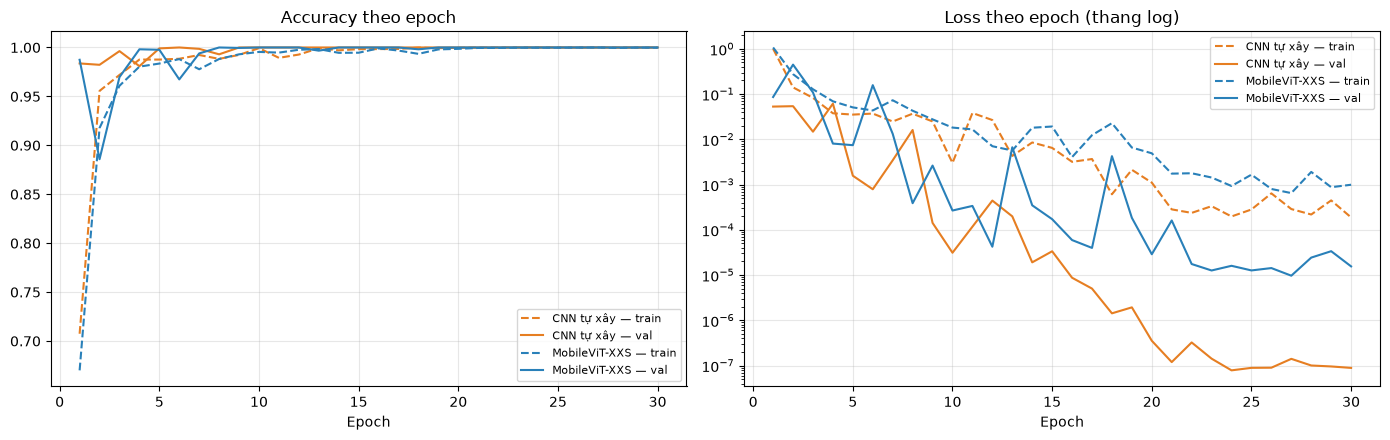

In [13]:
# Đường cong học: nét đứt = train, nét liền = validation
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, h in histories.items():
    ep = np.arange(1, len(h["loss"]) + 1)
    axes[0].plot(ep, h["accuracy"], "--", color=colors[name], label=f"{name} — train")
    axes[0].plot(ep, h["val_accuracy"], "-", color=colors[name], label=f"{name} — val")
    axes[1].plot(ep, h["loss"], "--", color=colors[name], label=f"{name} — train")
    axes[1].plot(ep, h["val_loss"], "-", color=colors[name], label=f"{name} — val")
axes[0].set_title("Accuracy theo epoch"); axes[1].set_title("Loss theo epoch (thang log)")
axes[1].set_yscale("log")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); savefig("04_learning_curves.png"); plt.show()

## 5. Đánh giá trên tập Test

Các chỉ số:
- **Accuracy**: tỷ lệ ảnh đoán đúng.
- **Macro-F1**: trung bình F1 của 15 lớp, **mỗi lớp có trọng số như nhau** → công bằng hơn accuracy khi số ảnh mỗi lớp chênh nhau nhiều (ví dụ lớp có ~600 ảnh test và lớp chỉ có ~50).
- **Kiểm định McNemar**: 2 mô hình được chấm trên **cùng** các ảnh test; kiểm định này trả lời *"chênh lệch accuracy có thật sự có ý nghĩa thống kê không, hay chỉ do may rủi?"* (p < 0,05 ⇒ có ý nghĩa).
- **Độ tự tin (confidence)** trung bình khi đoán đúng / đoán sai.

===== CNN tự xây =====
                     precision    recall  f1-score   support

    Apple Pink Lady     1.0000    1.0000    1.0000       152
          Apple Red     1.0000    1.0000    1.0000       472
Apple Red Delicious     1.0000    1.0000    1.0000       166
      Cabbage white     1.0000    1.0000    1.0000        47
       Cactus fruit     1.0000    1.0000    1.0000       166
          Caju seed     1.0000    1.0000    1.0000        75
          Carambola     1.0000    1.0000    1.0000       642
        Cherry Sour     1.0000    1.0000    1.0000       150
         Grape Blue     1.0000    1.0000    1.0000       328
        Grape White     1.0000    1.0000    1.0000       654
   Grapefruit White     1.0000    1.0000    1.0000       164
        Huckleberry     1.0000    1.0000    1.0000       166
             Lychee     1.0000    1.0000    1.0000       166
           Physalis     1.0000    1.0000    1.0000       164
           Zucchini     1.0000    1.0000    1.0000        80


I0000 00:00:1791861583.839787   71913 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_144', 72 bytes spill stores, 40 bytes spill loads



===== MobileViT-XXS =====
                     precision    recall  f1-score   support

    Apple Pink Lady     1.0000    1.0000    1.0000       152
          Apple Red     1.0000    1.0000    1.0000       472
Apple Red Delicious     1.0000    1.0000    1.0000       166
      Cabbage white     1.0000    1.0000    1.0000        47
       Cactus fruit     1.0000    1.0000    1.0000       166
          Caju seed     1.0000    1.0000    1.0000        75
          Carambola     1.0000    1.0000    1.0000       642
        Cherry Sour     1.0000    1.0000    1.0000       150
         Grape Blue     1.0000    1.0000    1.0000       328
        Grape White     1.0000    1.0000    1.0000       654
   Grapefruit White     1.0000    1.0000    1.0000       164
        Huckleberry     1.0000    1.0000    1.0000       166
             Lychee     1.0000    1.0000    1.0000       166
           Physalis     1.0000    1.0000    1.0000       164
           Zucchini     1.0000    1.0000    1.0000        

,CNN tự xây,MobileViT-XXS
Accuracy,100.00%,100.00%
Macro-F1,100.00%,100.00%
Số ảnh đoán sai,0 / 3592,0 / 3592
Độ tự tin TB khi đúng,100.0%,100.0%
Độ tự tin TB khi sai,—,—


McNemar: CNN đúng & MobileViT sai = 0 ảnh | CNN sai & MobileViT đúng = 0 ảnh | p-value = 1.0000
⇒ Chênh lệch KHÔNG có ý nghĩa thống kê (p ≥ 0.05): chưa đủ bằng chứng để nói mô hình nào chính xác hơn trên Test sạch
Đã lưu hình: /home/tranduydang/fruit-cnn-project/results/05_confusion_matrices.png


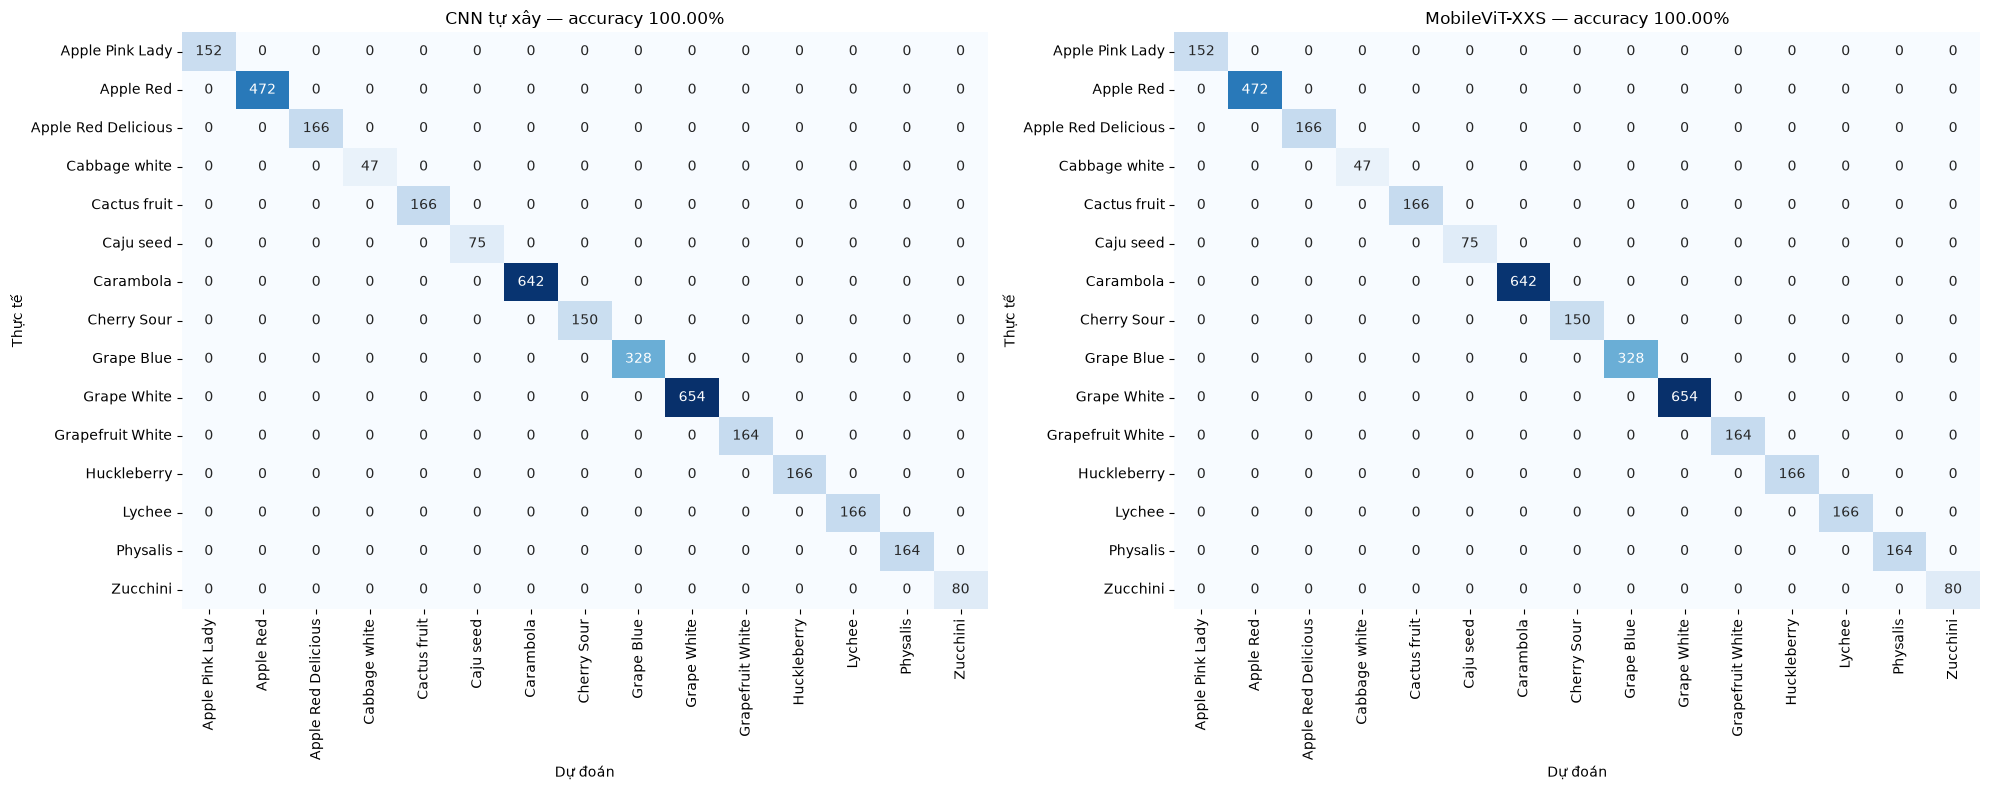

CNN tự xây: không đoán sai ảnh nào trên tập Test 🎉
MobileViT-XXS: không đoán sai ảnh nào trên tập Test 🎉


In [14]:
y_true = test_labels
eval_results = {}
for name, model in trained.items():
    probs = model.predict(test_ds, verbose=0)
    y_pred = probs.argmax(1)
    conf = probs.max(1)
    ok = y_pred == y_true
    eval_results[name] = {
        "probs": probs, "y_pred": y_pred,
        "acc": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro"),
        "n_wrong": int((~ok).sum()),
        "conf_correct": float(conf[ok].mean()) if ok.any() else float("nan"),
        "conf_wrong": float(conf[~ok].mean()) if (~ok).any() else float("nan"),
    }
    print(f"===== {name} =====")
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4, zero_division=0))

# Kiểm định McNemar (exact): chỉ xét các ảnh mà 2 model "bất đồng"
ok_cnn = eval_results[CNN_NAME]["y_pred"] == y_true
ok_mvit = eval_results[MVIT_NAME]["y_pred"] == y_true
mc_b = int((ok_cnn & ~ok_mvit).sum())   # CNN đúng, MobileViT sai
mc_c = int((~ok_cnn & ok_mvit).sum())   # CNN sai, MobileViT đúng
mcnemar_p = float(stats.binomtest(min(mc_b, mc_c), mc_b + mc_c, 0.5).pvalue) if mc_b + mc_c > 0 else 1.0

summary_test = pd.DataFrame({
    name: {"Accuracy": f"{r['acc']*100:.2f}%", "Macro-F1": f"{r['macro_f1']*100:.2f}%",
           "Số ảnh đoán sai": f"{r['n_wrong']} / {len(y_true)}",
           "Độ tự tin TB khi đúng": f"{r['conf_correct']*100:.1f}%",
           "Độ tự tin TB khi sai": f"{r['conf_wrong']*100:.1f}%" if r["n_wrong"] else "—"}
    for name, r in eval_results.items()})
display(summary_test)
print(f"McNemar: CNN đúng & MobileViT sai = {mc_b} ảnh | CNN sai & MobileViT đúng = {mc_c} ảnh | p-value = {mcnemar_p:.4f}")
print("⇒ Chênh lệch CÓ ý nghĩa thống kê (p < 0.05)" if mcnemar_p < 0.05
      else "⇒ Chênh lệch KHÔNG có ý nghĩa thống kê (p ≥ 0.05): chưa đủ bằng chứng để nói mô hình nào chính xác hơn trên Test sạch")

# Confusion matrix đặt cạnh nhau
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, (name, r) in zip(axes, eval_results.items()):
    cm = confusion_matrix(y_true, r["y_pred"], labels=range(num_classes))
    sns.heatmap(cm, annot=num_classes <= 20, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=class_names, yticklabels=class_names)
    ax.set_title(f"{name} — accuracy {r['acc']*100:.2f}%")
    ax.set_xlabel("Dự đoán"); ax.set_ylabel("Thực tế")
    ax.tick_params(axis="x", rotation=90); ax.tick_params(axis="y", rotation=0)
plt.tight_layout(); savefig("05_confusion_matrices.png"); plt.show()

# Một số ảnh bị đoán sai của mỗi mô hình
for name, r in eval_results.items():
    wrong = np.where(r["y_pred"] != y_true)[0]
    if len(wrong) == 0:
        print(f"{name}: không đoán sai ảnh nào trên tập Test 🎉"); continue
    show = wrong[:8]
    fig, axes = plt.subplots(1, len(show), figsize=(2.3 * len(show), 2.9), squeeze=False)
    for ax, i in zip(axes[0], show):
        ax.imshow(load_image(test_paths[i], 0)[0].numpy()); ax.axis("off")
        ax.set_title(f"Thật: {class_names[y_true[i]]}\nĐoán: {class_names[r['y_pred'][i]]}\n"
                     f"({r['probs'][i].max()*100:.0f}%)", fontsize=7, color="#c0392b")
    plt.suptitle(f"{name}: {len(wrong)} ảnh đoán sai (hiện tối đa 8)", fontsize=10)
    plt.tight_layout(); plt.show()

## 6. Hiệu năng: tham số, dung lượng, FLOPs, tốc độ

Khi accuracy đã gần 100%, câu hỏi thực tế là: **mô hình nào nhẹ hơn, rẻ hơn, nhanh hơn?** (MobileViT được thiết kế cho điện thoại, nên đây là tiêu chí quan trọng.)
- **Số tham số / dung lượng**: tốn bao nhiêu bộ nhớ để lưu mô hình.
- **FLOPs**: số phép tính dấu phẩy động cho 1 ảnh (FLOPs ≈ 2 × số phép nhân-cộng). Đếm trực tiếp từ kích thước từng lớp Conv / Depthwise / Dense / Attention.
- **Độ trễ (latency)**: thời gian thật để dự đoán 1 ảnh, đo trên GPU và CPU (CPU gần với điều kiện thiết bị di động hơn).

> Lưu ý: FLOPs ít hơn **không** có nghĩa là chạy nhanh hơn. Tốc độ thật còn phụ thuộc số lớp nối tiếp nhau, các phép reshape/transpose, và việc phần cứng/thư viện tối ưu cho loại phép toán nào (Conv rất được tối ưu trên GPU).

In [15]:
def count_macs(model, input_shape):
    """Đếm số phép nhân-cộng (MACs) cho 1 ảnh bằng cách duyệt từng lớp.
    FLOPs ≈ 2 × MACs. Chỉ tính các lớp nặng (Conv, Depthwise, Dense, Attention);
    BatchNorm/activation/pooling rất nhỏ nên bỏ qua.
    Chạy thử 1 ảnh qua model để lấy kích thước tensor THẬT của từng lớp
    (quan trọng với MobileViT: sau Unfold, batch 1 ảnh trở thành P = 4 chuỗi)."""
    heavy = [l for l in model.layers
             if isinstance(l, (layers.Conv2D, layers.DepthwiseConv2D, layers.Dense, layers.MultiHeadAttention))]
    probe = keras.Model(model.input, [l.output for l in heavy])
    outs = probe(np.zeros((1, *input_shape), "float32"), training=False)
    outs = outs if isinstance(outs, (list, tuple)) else [outs]
    per_layer = {}
    for l, o in zip(heavy, outs):
        s = tuple(o.shape)
        if isinstance(l, layers.DepthwiseConv2D):            # kiểm tra Depthwise trước Conv2D cho chắc
            kh, kw = l.kernel_size
            macs = s[0] * s[1] * s[2] * s[3] * kh * kw
        elif isinstance(l, layers.Conv2D):
            kh, kw = l.kernel_size
            cin = l.kernel.shape[2]                          # = C_in / groups
            macs = s[0] * s[1] * s[2] * s[3] * kh * kw * cin
        elif isinstance(l, layers.Dense):
            macs = int(np.prod(s[:-1])) * l.kernel.shape[0] * l.kernel.shape[1]
        else:                                                # MultiHeadAttention, input = output = [b, N, d]
            b, n, d = s
            hk = l.num_heads * l.key_dim
            proj = 3 * b * n * d * hk + b * n * hk * d       # Q, K, V và output projection
            attn = 2 * b * l.num_heads * n * n * l.key_dim  # QK^T và (softmax)·V
            macs = proj + attn
        per_layer[l.name] = int(macs)
    return sum(per_layer.values()), per_layer

Đã đo xong CNN tự xây
Đã đo xong MobileViT-XXS


,Số tham số (triệu),Dung lượng float32 (MB),GFLOPs / ảnh,Thời gian train (s/epoch),Epoch tốt nhất,GPU — 1 ảnh (ms),GPU — batch 32 (ảnh/giây),CPU — 1 ảnh (ms)
CNN tự xây,3.307,13.226,0.287,4.168,24.0,1.369,8701.286,347.130
MobileViT-XXS,0.960,3.840,0.174,8.155,27.0,12.485,1941.969,135.855


Đã lưu hình: /home/tranduydang/fruit-cnn-project/results/06_efficiency.png


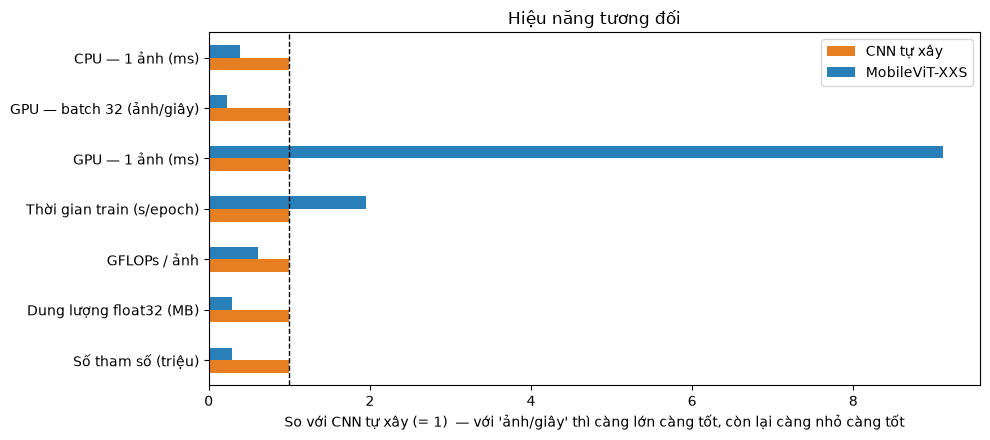

In [16]:
def weights_size_mb(model):
    """Dung lượng trọng số khi lưu dạng float32 (4 byte / tham số), không tính trạng thái optimizer."""
    return model.count_params() * 4 / 1e6

def measure_latency_ms(model, batch_size=1, device="/CPU:0", n_warmup=10, n_runs=LATENCY_RUNS):
    """Thời gian suy luận (ms) cho 1 batch, lấy trung vị của n_runs lần đo (đã chạy nháp trước)."""
    with tf.device(device):
        m = keras.models.clone_model(model)          # bản sao nằm hẳn trên thiết bị cần đo
        m.set_weights(model.get_weights())
        x = tf.random.uniform((batch_size, *IMG_SIZE, 3), 0, 255)
        f = tf.function(lambda t: m(t, training=False))
        for _ in range(n_warmup):
            f(x).numpy()
        ts = []
        for _ in range(n_runs):
            t0 = time.perf_counter()
            f(x).numpy()
            ts.append((time.perf_counter() - t0) * 1000)
    return float(np.median(ts))

bench = {}
for name, model in trained.items():
    macs, _ = count_macs(model, IMG_SIZE + (3,))
    row = {"Số tham số (triệu)": model.count_params() / 1e6,
           "Dung lượng float32 (MB)": weights_size_mb(model),
           "GFLOPs / ảnh": 2 * macs / 1e9,
           "Thời gian train (s/epoch)": train_info[name]["epoch_time_s"],
           "Epoch tốt nhất": train_info[name]["best_epoch"]}
    if gpus:
        row["GPU — 1 ảnh (ms)"] = measure_latency_ms(model, 1, "/GPU:0")
        b32 = measure_latency_ms(model, 32, "/GPU:0")
        row["GPU — batch 32 (ảnh/giây)"] = 32 / (b32 / 1000)
    row["CPU — 1 ảnh (ms)"] = measure_latency_ms(model, 1, "/CPU:0")
    bench[name] = row
    print(f"Đã đo xong {name}")

bench_df = pd.DataFrame(bench).T
display(bench_df.round(3))

# Biểu đồ tương đối (CNN = 1)
metrics_plot = [c for c in bench_df.columns if c != "Epoch tốt nhất"]
rel = bench_df[metrics_plot] / bench_df.loc[CNN_NAME, metrics_plot]
ax = rel.T.plot(kind="barh", figsize=(10, 4.5), color=[colors[n] for n in rel.index])
ax.axvline(1, color="black", lw=1, ls="--")
ax.set_xlabel("So với CNN tự xây (= 1)  — với 'ảnh/giây' thì càng lớn càng tốt, còn lại càng nhỏ càng tốt")
ax.set_title("Hiệu năng tương đối")
plt.tight_layout(); savefig("06_efficiency.png"); plt.show()

## 7. Thí nghiệm A — Khi chỉ có ít dữ liệu

Huấn luyện lại **từ đầu** cả 2 mô hình với chỉ **2%, 5%, 10%, 25%** ảnh train (chọn phân tầng để lớp nào cũng có), giữ nguyên tập val/test và công thức huấn luyện. Điểm 100% lấy từ lần huấn luyện chính ở mục 4.

**Câu hỏi:** Transformer thường "đói dữ liệu". MobileViT vẫn giữ convolution — vậy nó có học được khi ít ảnh không, hay CNN đơn giản lại tốt hơn?

> Lưu ý khi diễn giải: cùng số epoch thì ít ảnh ⇒ **ít bước cập nhật trọng số** hơn (2% dữ liệu chỉ ~6 batch/epoch). Mô hình có Transformer thường hội tụ chậm hơn, nên kết quả ở đây phản ánh cả "cần nhiều dữ liệu" lẫn "cần nhiều bước học" — cả hai đều là đặc điểm thật của Transformer.
>
> Với tỷ lệ nhỏ, kết quả dao động khá nhiều theo việc chọn ngẫu nhiên ảnh nào. Đặt `N_REPEATS = 3` ở ô cấu hình để lặp lại 3 lần và có thanh sai số (tốn thêm thời gian).

   2% (172 ảnh) | lần 0 | CNN tự xây       | acc =  96.21% | 30 epoch, 23s


I0000 00:00:1791861688.154967   76274 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'input_add_multiply_reduce_select_fusion', 76 bytes spill stores, 52 bytes spill loads

I0000 00:00:1791861688.288368   76274 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'input_add_multiply_reduce_fusion_1', 64 bytes spill stores, 44 bytes spill loads

W0000 00:00:1791861690.054118   56520 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1791861657326134359 in buffer 'PrefetchDataset/_24' sat unconsumed for 32.728 seconds!
I0000 00:00:1791861715.396251   76886 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_78', 4 bytes spill stores, 4 bytes spill loads

I0000 00:00:1791861715.506973   76878 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_259', 72 bytes spill st

   2% (172 ảnh) | lần 0 | MobileViT-XXS    | acc =  95.91% | 28 epoch, 123s
   5% (429 ảnh) | lần 0 | CNN tự xây       | acc =  99.33% | 26 epoch, 24s


I0000 00:00:1791861837.276108   85702 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'input_add_multiply_reduce_select_fusion', 76 bytes spill stores, 52 bytes spill loads

I0000 00:00:1791861837.342699   85692 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'input_add_multiply_reduce_fusion_1', 64 bytes spill stores, 44 bytes spill loads

W0000 00:00:1791861839.604562   56520 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1791861806743893760 in buffer 'PrefetchDataset/_24' sat unconsumed for 32.8535 seconds!
I0000 00:00:1791861864.592871   86310 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_117', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1791861871.035845   86301 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_258', 48 bytes spill 

   5% (429 ảnh) | lần 0 | MobileViT-XXS    | acc =  99.22% | 30 epoch, 133s


...

  10% (858 ảnh) | lần 0 | MobileViT-XXS    | acc =  99.78% | 30 epoch, 147s
  25% (2146 ảnh) | lần 0 | CNN tự xây       | acc = 100.00% | 20 epoch, 38s


I0000 00:00:1791862200.193593  104768 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'input_add_multiply_reduce_select_fusion', 76 bytes spill stores, 52 bytes spill loads

I0000 00:00:1791862200.970555  104775 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'input_add_multiply_reduce_fusion_1', 64 bytes spill stores, 44 bytes spill loads

W0000 00:00:1791862206.165508   56520 prefetch_dataset_op.cc:476] SEVERE STARVATION: Element UID 1791862163959465432 in buffer 'PrefetchDataset/_24' sat unconsumed for 42.206 seconds!
I0000 00:00:1791862238.319025  105395 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_368', 4 bytes spill stores, 4 bytes spill loads

I0000 00:00:1791862240.857176  105401 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_78', 4 bytes spill 

  25% (2146 ảnh) | lần 0 | MobileViT-XXS    | acc =  99.58% | 30 epoch, 200s


mean              
Mô hình      CNN tự xây MobileViT-XXS
Số ảnh train                         
172               96.21         95.91
429               99.33         99.22
858              100.00         99.78
2146             100.00         99.58
8583             100.00        100.00

Đã lưu hình: /home/tranduydang/fruit-cnn-project/results/07_data_efficiency.png


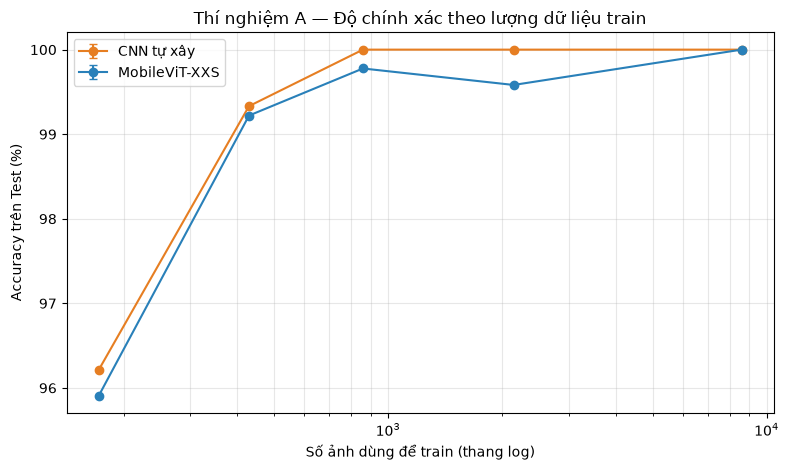

In [17]:
eff_rows = []
for name in trained:   # điểm 100% lấy từ lần train chính
    eff_rows.append({"Mô hình": name, "Tỷ lệ dữ liệu": 1.0, "Số ảnh train": len(train_paths), "Lần": 0,
                     "Accuracy": eval_results[name]["acc"], "Macro-F1": eval_results[name]["macro_f1"]})

if RUN_DATA_EFFICIENCY:
    for frac in DATA_FRACTIONS:
        for rep in range(N_REPEATS):
            n_sub = max(int(round(frac * len(train_paths))), num_classes)
            sub_idx, _ = train_test_split(np.arange(len(train_paths)), train_size=n_sub,
                                          stratify=train_labels, random_state=SEED + rep)
            sub_ds = make_dataset(train_paths[sub_idx], train_labels[sub_idx], training=True)
            for name, build in MODEL_BUILDERS.items():
                t0 = time.perf_counter()
                m, _, info = train_model(build, sub_ds, val_ds, verbose=0, seed=SEED + rep)
                y_pred = m.predict(test_ds, verbose=0).argmax(1)
                eff_rows.append({"Mô hình": name, "Tỷ lệ dữ liệu": frac, "Số ảnh train": n_sub, "Lần": rep,
                                 "Accuracy": accuracy_score(test_labels, y_pred),
                                 "Macro-F1": f1_score(test_labels, y_pred, average="macro")})
                print(f"{frac:>5.0%} ({n_sub} ảnh) | lần {rep} | {name:<16} | acc = {eff_rows[-1]['Accuracy']*100:6.2f}% "
                      f"| {info['epochs_run']} epoch, {time.perf_counter() - t0:.0f}s")
                del m
                gc.collect()

eff_df = pd.DataFrame(eff_rows)
aggs = ["mean", "std"] if N_REPEATS > 1 else ["mean"]
eff_table = eff_df.groupby(["Số ảnh train", "Mô hình"])["Accuracy"].agg(aggs).unstack("Mô hình") * 100
display(eff_table.round(2))

fig, ax = plt.subplots(figsize=(8, 4.8))
for name, g in eff_df.groupby("Mô hình"):
    s = g.groupby("Số ảnh train")["Accuracy"].agg(["mean", "std"]).fillna(0)
    ax.errorbar(s.index, s["mean"] * 100, yerr=s["std"] * 100, marker="o", capsize=3,
                color=colors[name], label=name)
ax.set_xscale("log"); ax.set_xlabel("Số ảnh dùng để train (thang log)"); ax.set_ylabel("Accuracy trên Test (%)")
ax.set_title("Thí nghiệm A — Độ chính xác theo lượng dữ liệu train"); ax.grid(alpha=0.3, which="both"); ax.legend()
plt.tight_layout(); savefig("07_data_efficiency.png"); plt.show()

## 8. Thí nghiệm B — Độ bền khi ảnh bị biến đổi

Ở notebook trước ta đã thấy: model đạt ~100% trên Test nhưng **đoán sai ảnh thật trên mạng** (quả chanh → "Cherry Rainier", cà chua vàng → "Apple Pink Lady"). Lý do: ảnh Fruits-360 luôn có **nền trắng tinh, ánh sáng đều, quả ở giữa** — ảnh thật thì không.

Thí nghiệm này **mô phỏng ảnh đời thật** bằng cách biến đổi chính tập Test (2 mô hình được chấm trên **đúng cùng các ảnh** đã biến đổi):

| Biến đổi | Mô phỏng tình huống |
|---|---|
| Nhiễu Gauss | camera kém, chụp thiếu sáng |
| Làm mờ | rung tay, lấy nét sai |
| Tối đi 50% / Giảm tương phản | ánh sáng yếu, ngược sáng |
| Xoay 45° | góc chụp khác |
| Che 48×48 px | quả bị che một phần |
| **Nền màu / nền hoa văn ngẫu nhiên** | quả đặt trên bàn, khăn, đĩa... (thay nền trắng bằng nền khác, **quả giữ nguyên**) |

Phép **đổi nền** là quan trọng nhất: nếu accuracy tụt mạnh ⇒ mô hình đã "học vẹt" cả nền trắng chứ không chỉ học hình dáng/màu của quả.

Nền chiếm trung bình 33% diện tích ảnh test
Đã lưu hình: /home/tranduydang/fruit-cnn-project/results/08_corruption_examples.png


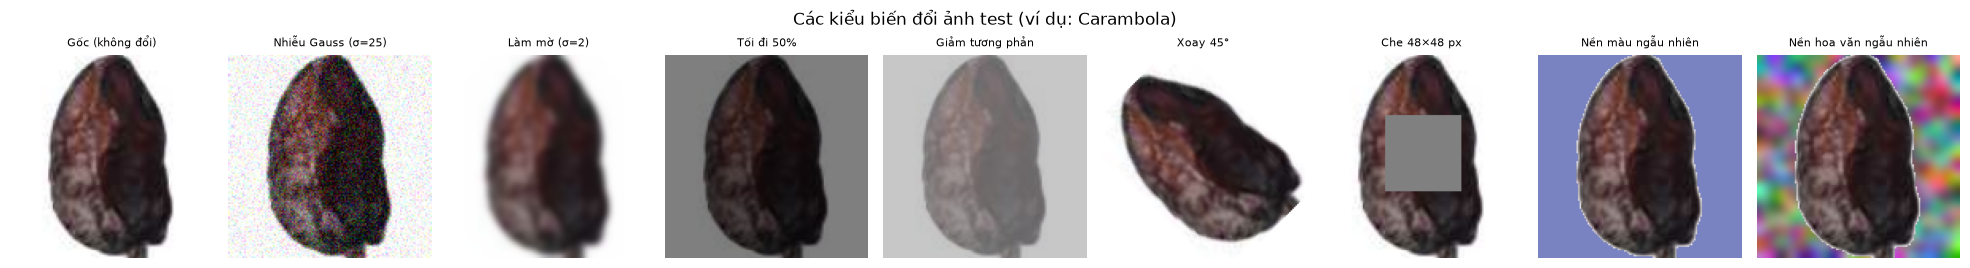

In [18]:
# Nạp toàn bộ ảnh Test vào RAM (uint8) để tạo các phiên bản bị biến đổi
X_test = np.concatenate([x.numpy() for x, _ in test_ds]).astype(np.uint8)

def background_mask(img, thr=225):
    """Nền = vùng gần trắng NỐI LIỀN với viền ảnh (để không 'ăn' vào phần trắng bên trong quả)."""
    near_white = img.min(axis=-1) > thr
    lab, _ = ndimage.label(near_white)
    border = np.unique(np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]]))
    return np.isin(lab, border[border > 0])

BG_MASKS = np.stack([background_mask(im) for im in X_test])
print(f"Nền chiếm trung bình {BG_MASKS.mean()*100:.0f}% diện tích ảnh test")

H, W = IMG_SIZE
def c_noise(x, m, rng):    return x + rng.normal(0, 25, x.shape)
def c_blur(x, m, rng):     return ndimage.gaussian_filter(x, sigma=(0, 2, 2, 0))
def c_dark(x, m, rng):     return x * 0.5
def c_contrast(x, m, rng):
    mean = x.mean(axis=(1, 2, 3), keepdims=True)
    return mean + (x - mean) * 0.4
def c_rotate(x, m, rng):   return ndimage.rotate(x, 45, axes=(1, 2), reshape=False, order=1, cval=255.0)
def c_cutout(x, m, rng, s=48):
    x = x.copy()
    for i in range(len(x)):
        r, c = rng.integers(0, H - s + 1), rng.integers(0, W - s + 1)
        x[i, r:r + s, c:c + s] = 128.0
    return x
def c_bg_color(x, m, rng):
    colors_ = rng.integers(0, 256, (len(x), 1, 1, 3)).astype("float32")
    return np.where(m[..., None], colors_, x)
def c_bg_texture(x, m, rng):
    tex = ndimage.gaussian_filter(rng.uniform(0, 255, x.shape), sigma=(0, 4, 4, 0))
    tex = (tex - tex.mean(axis=(1, 2), keepdims=True)) * 6 + 128     # tăng tương phản cho rõ hoa văn
    return np.where(m[..., None], np.clip(tex, 0, 255), x)

CORRUPTIONS = {
    "Gốc (không đổi)": lambda x, m, rng: x,
    "Nhiễu Gauss (σ=25)": c_noise,
    "Làm mờ (σ=2)": c_blur,
    "Tối đi 50%": c_dark,
    "Giảm tương phản": c_contrast,
    "Xoay 45°": c_rotate,
    "Che 48×48 px": c_cutout,
    "Nền màu ngẫu nhiên": c_bg_color,
    "Nền hoa văn ngẫu nhiên": c_bg_texture,
}

# Minh hoạ: cùng 1 ảnh qua từng kiểu biến đổi
bg_frac = BG_MASKS.mean(axis=(1, 2))
cand = np.where((bg_frac > 0.4) & (bg_frac < 0.8))[0]      # chọn ảnh có nền vừa phải để minh hoạ cho rõ
i0 = int(cand[len(cand) // 2]) if len(cand) else 0
fig, axes = plt.subplots(1, len(CORRUPTIONS), figsize=(2.2 * len(CORRUPTIONS), 2.7))
for ax, (cname, fn) in zip(axes, CORRUPTIONS.items()):
    img = np.clip(fn(X_test[i0:i0 + 1].astype("float32"), BG_MASKS[i0:i0 + 1], np.random.default_rng(1)), 0, 255)
    ax.imshow(img[0].astype("uint8")); ax.set_title(cname, fontsize=8); ax.axis("off")
plt.suptitle(f"Các kiểu biến đổi ảnh test (ví dụ: {class_names[test_labels[i0]]})")
plt.tight_layout(); savefig("08_corruption_examples.png"); plt.show()

I0000 00:00:1791862378.560805  110807 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot', 8 bytes spill stores, 8 bytes spill loads

I0000 00:00:1791862378.727705  110809 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot', 40 bytes spill stores, 40 bytes spill loads

W0000 00:00:1791862383.286934  110987 cuda_timer.cc:88] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1791862383.977206  110994 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_192', 96 bytes spill stores, 48 bytes spill loads

I0000 00:00:1791862385.224352  110984 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_144', 72 bytes spill stores, 40 bytes spill 

Gốc (không đổi)         CNN tự xây: 100.00%  MobileViT-XXS: 100.00%
Nhiễu Gauss (σ=25)      CNN tự xây:  95.57%  MobileViT-XXS:  56.46%
Làm mờ (σ=2)            CNN tự xây:  99.55%  MobileViT-XXS:  99.75%
Tối đi 50%              CNN tự xây:  62.61%  MobileViT-XXS:  21.77%
Giảm tương phản         CNN tự xây:  25.75%  MobileViT-XXS:  29.68%
Xoay 45°                CNN tự xây:  99.30%  MobileViT-XXS: 100.00%
Che 48×48 px            CNN tự xây:  99.69%  MobileViT-XXS:  99.33%
Nền màu ngẫu nhiên      CNN tự xây:  91.34%  MobileViT-XXS:  66.12%
Nền hoa văn ngẫu nhiên  CNN tự xây:  99.33%  MobileViT-XXS:  91.82%


,CNN tự xây,MobileViT-XXS,Chênh lệch (MobileViT − CNN)
Gốc (không đổi),100.00,100.00,0.00
Nhiễu Gauss (σ=25),95.57,56.46,-39.11
Làm mờ (σ=2),99.55,99.75,0.19
Tối đi 50%,62.61,21.77,-40.84
Giảm tương phản,25.75,29.68,3.93
Xoay 45°,99.30,100.00,0.70
Che 48×48 px,99.69,99.33,-0.36
Nền màu ngẫu nhiên,91.34,66.12,-25.22
Nền hoa văn ngẫu nhiên,99.33,91.82,-7.52


Đã lưu hình: /home/tranduydang/fruit-cnn-project/results/09_robustness.png


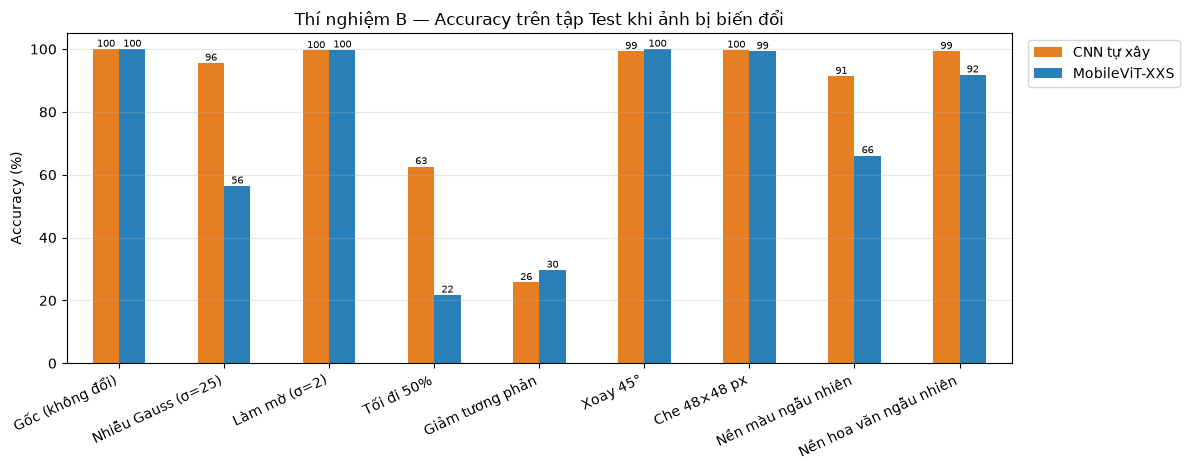

In [19]:
rob = {name: {} for name in trained}
for cname, fn in CORRUPTIONS.items():
    rng = np.random.default_rng(SEED)            # cùng seed -> 2 mô hình thấy CHÍNH XÁC cùng ảnh biến đổi
    correct = {name: 0 for name in trained}
    for s in range(0, len(X_test), 256):
        xc = np.clip(fn(X_test[s:s + 256].astype("float32"), BG_MASKS[s:s + 256], rng), 0, 255).astype("float32")
        for name, model in trained.items():
            correct[name] += int((model.predict(xc, batch_size=128, verbose=0).argmax(1)
                                  == test_labels[s:s + 256]).sum())
    for name in trained:
        rob[name][cname] = correct[name] / len(X_test)
    print(f"{cname:<24}" + "  ".join(f"{n}: {rob[n][cname]*100:6.2f}%" for n in trained))

rob_df = pd.DataFrame(rob) * 100
rob_df["Chênh lệch (MobileViT − CNN)"] = rob_df[MVIT_NAME] - rob_df[CNN_NAME]
display(rob_df.round(2))

ax = rob_df[[CNN_NAME, MVIT_NAME]].plot(kind="bar", figsize=(12, 4.8), color=[colors[CNN_NAME], colors[MVIT_NAME]])
ax.set_ylabel("Accuracy (%)"); ax.set_ylim(0, 105); ax.grid(axis="y", alpha=0.3)
ax.set_title("Thí nghiệm B — Accuracy trên tập Test khi ảnh bị biến đổi")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.0f", fontsize=7)
plt.xticks(rotation=25, ha="right"); plt.tight_layout(); savefig("09_robustness.png"); plt.show()

## 9. Thí nghiệm C — Ảnh thật ngoài dataset

Ô dưới đây tự tạo thư mục `external_test/<tên lớp>/` trong folder project. Bạn chép **ảnh thật** (tự chụp bằng điện thoại hoặc tải trên mạng) của các loại quả **có trong 15 lớp** vào đúng thư mục, mỗi loại khoảng 5–10 ảnh, rồi chạy lại ô này.

> Lưu ý: mô hình chỉ biết 15 loại đã học (*closed-set*). Đưa ảnh loại quả khác vào thì nó **vẫn buộc phải chọn 1 trong 15 lớp** — đó không phải lỗi mà là giới hạn của bài toán phân loại.

Hàm `predict_image(đường_dẫn)` dùng để **demo trực tiếp khi thuyết trình**: hiện top-3 dự đoán của cả 2 mô hình cho 1 ảnh bất kỳ.

Tìm thấy 24 ảnh ngoài trong /home/tranduydang/fruit-cnn-project/external_test


I0000 00:00:1791905781.467812   43675 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot', 12 bytes spill stores, 12 bytes spill loads



CNN tự xây: đúng 6/24 ảnh = 25.0%  (so với Test: 100.0%)


I0000 00:00:1791905788.100400   43859 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_144', 72 bytes spill stores, 40 bytes spill loads

I0000 00:00:1791905789.396934   43860 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_192', 72 bytes spill stores, 40 bytes spill loads

I0000 00:00:1791905789.970951   43865 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_192', 96 bytes spill stores, 48 bytes spill loads



MobileViT-XXS: đúng 6/24 ảnh = 25.0%  (so với Test: 100.0%)
Đã lưu hình: /home/tranduydang/fruit-cnn-project/results/10_external.png


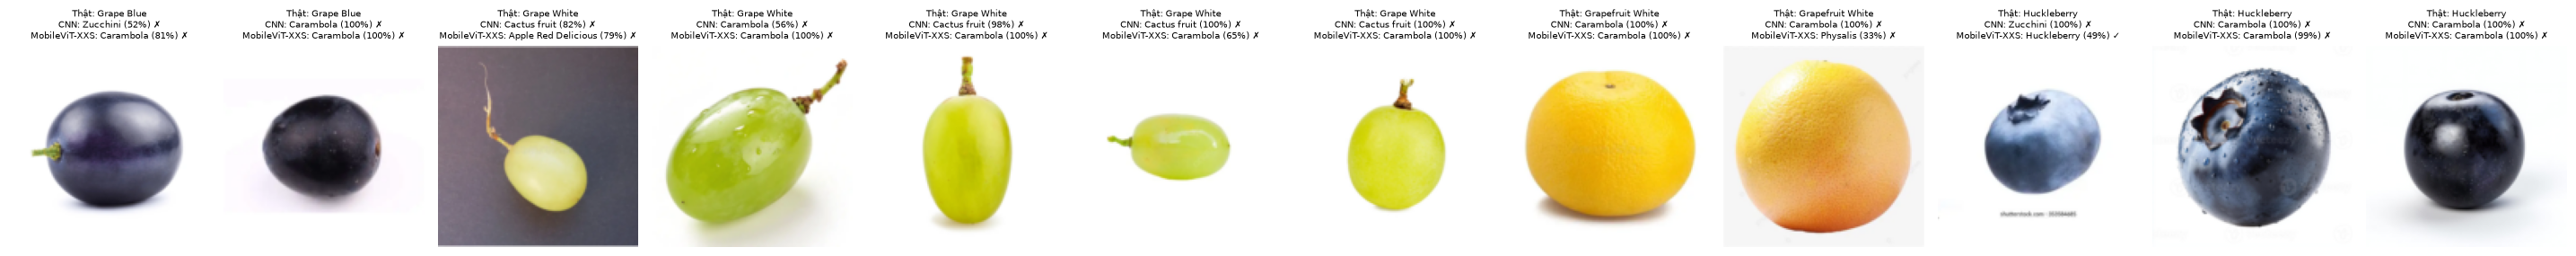


Demo 6 ảnh trong /home/tranduydang/fruit-cnn-project/test_images


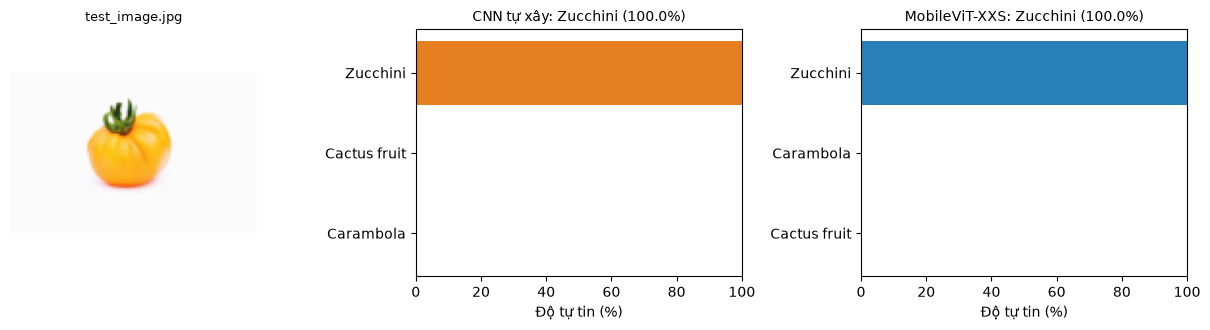

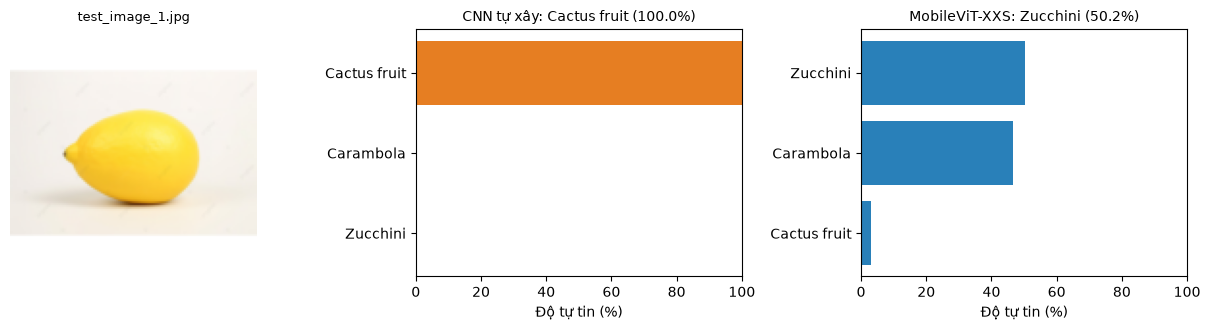

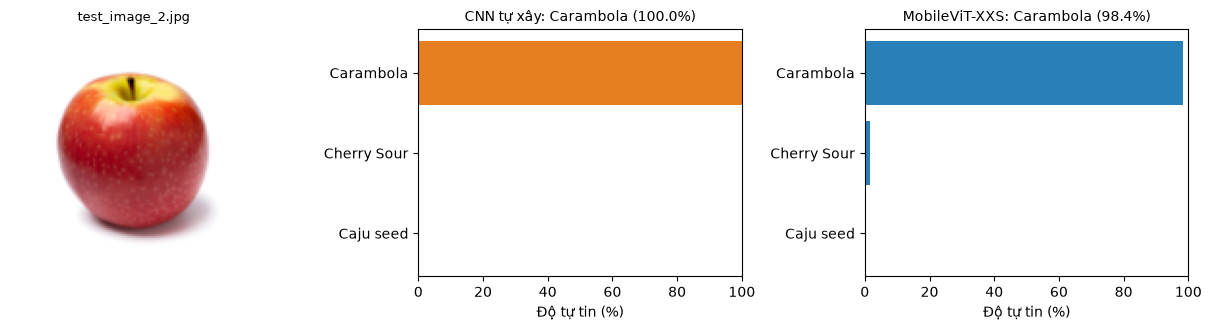

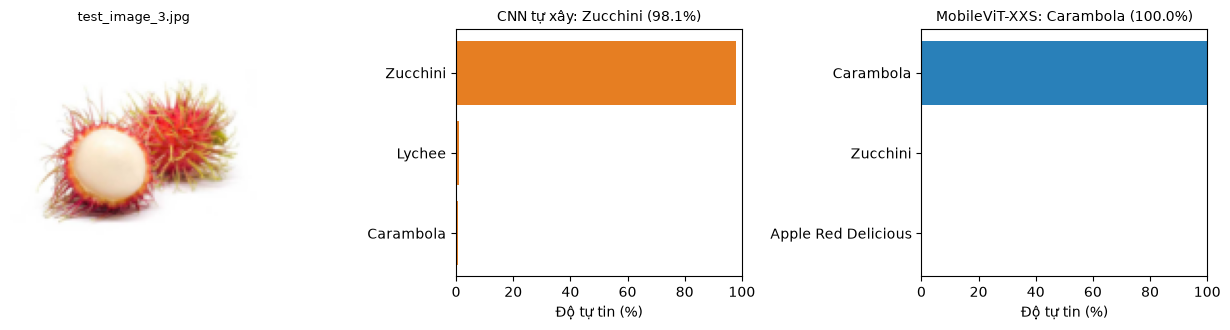

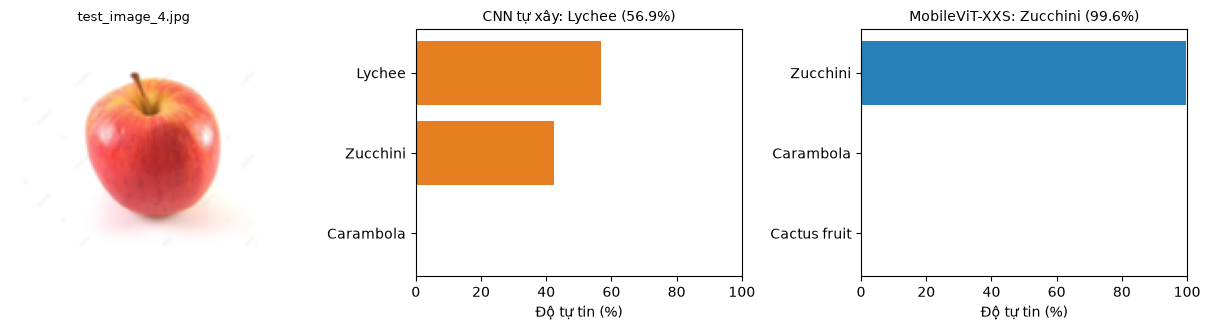

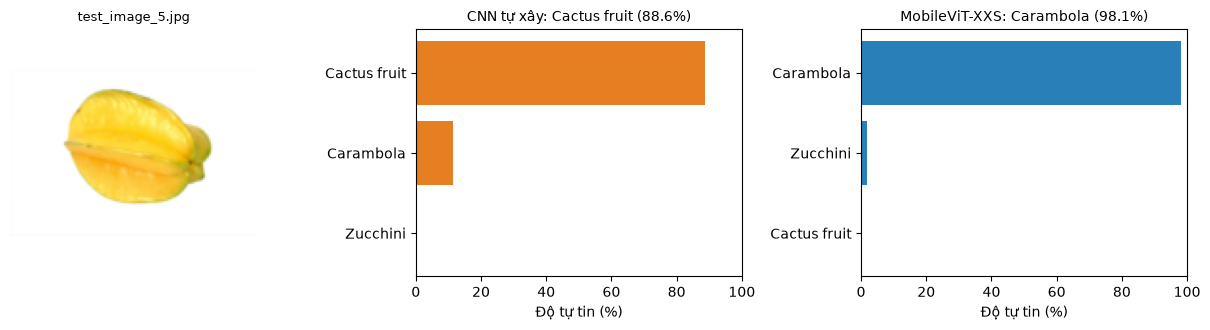

In [11]:
def load_for_model(path):
    """Ảnh ngoài đời thường không vuông: đệm nền TRẮNG cho vuông rồi resize (giống cách ảnh Fruits-360 được chụp)."""
    img = Image.open(path).convert("RGB")
    side = max(img.size)
    canvas = Image.new("RGB", (side, side), (255, 255, 255))
    canvas.paste(img, ((side - img.size[0]) // 2, (side - img.size[1]) // 2))
    return np.asarray(canvas.resize(IMG_SIZE, Image.BILINEAR), dtype="float32")

def predict_image(path, top_k=3):
    """Demo: dự đoán 1 ảnh bằng cả 2 mô hình, hiện top-3 kèm độ tự tin."""
    x = load_for_model(path)
    fig, axes = plt.subplots(1, 1 + len(trained), figsize=(4.2 * (1 + len(trained)), 3.4))
    axes[0].imshow(x.astype("uint8")); axes[0].axis("off"); axes[0].set_title(os.path.basename(path), fontsize=9)
    for ax, (name, model) in zip(axes[1:], trained.items()):
        p = model.predict(x[None], verbose=0)[0]
        top = np.argsort(p)[::-1][:top_k]
        ax.barh([class_names[t] for t in top][::-1], p[top][::-1] * 100, color=colors[name])
        ax.set_xlim(0, 100); ax.set_xlabel("Độ tự tin (%)")
        ax.set_title(f"{name}: {class_names[top[0]]} ({p[top[0]]*100:.1f}%)", fontsize=10)
    plt.tight_layout(); plt.show()

# Tạo sẵn thư mục external_test/<tên lớp>/ để bạn chép ảnh vào
for c in class_names:
    os.makedirs(os.path.join(EXTERNAL_DIR, c), exist_ok=True)
ext_paths, ext_labels, _ = list_images(EXTERNAL_DIR, class_names)
print(f"Tìm thấy {len(ext_paths)} ảnh ngoài trong {EXTERNAL_DIR}")

ext_acc = {}
if len(ext_paths) == 0:
    print("➡ Chưa có ảnh. Hãy chép ảnh thật (tự chụp / tải trên mạng) vào đúng thư mục con theo tên loại quả,\n"
          "  ví dụ external_test/Lychee/vai1.jpg, rồi chạy lại ô này. Chỉ dùng các loại có trong 15 lớp đã train.")
else:
    X_ext = np.stack([load_for_model(p) for p in ext_paths])
    ext_pred = {}
    for name, model in trained.items():
        probs = model.predict(X_ext, verbose=0)
        ext_pred[name] = probs
        ext_acc[name] = accuracy_score(ext_labels, probs.argmax(1))
        print(f"{name}: đúng {int((probs.argmax(1) == ext_labels).sum())}/{len(ext_labels)} ảnh "
              f"= {ext_acc[name]*100:.1f}%  (so với Test: {eval_results[name]['acc']*100:.1f}%)")
    n_show = min(len(ext_paths), 12)
    fig, axes = plt.subplots(1, n_show, figsize=(2.4 * n_show, 3.4), squeeze=False)
    for ax, i in zip(axes[0], range(n_show)):
        ax.imshow(X_ext[i].astype("uint8")); ax.axis("off")
        lines = [f"Thật: {class_names[ext_labels[i]]}"]
        for name, probs in ext_pred.items():
            k = probs[i].argmax()
            lines.append(f"{name.split()[0]}: {class_names[k]} ({probs[i, k]*100:.0f}%)"
                         + (" ✓" if k == ext_labels[i] else " ✗"))
        ax.set_title("\n".join(lines), fontsize=7)
    plt.tight_layout(); savefig("10_external.png"); plt.show()

# Demo: dự đoán các ảnh bạn đã tự lưu trong thư mục test_images/ (không cần biết nhãn)
# Lưu ý: chỉ ảnh thuộc 15 lớp đang train mới có thể đoán đúng (vd ảnh chanh, cà chua cũ KHÔNG còn trong 15 lớp)
DEMO_DIR = os.path.join(BASE_DIR, "test_images")
demo_imgs = sorted(f for f in os.listdir(DEMO_DIR) if f.lower().endswith(IMG_EXTS)) if os.path.isdir(DEMO_DIR) else []
print(f"\nDemo {len(demo_imgs)} ảnh trong {DEMO_DIR}")
for f in demo_imgs[:10]:
    predict_image(os.path.join(DEMO_DIR, f))

CNN tự xây: không cắt 25.0%  →  cắt sát 20.8%
   Lớp bị đoán nhiều nhất khi KHÔNG cắt: {'Zucchini': 8, 'Carambola': 8, 'Cactus fruit': 4}
MobileViT-XXS: không cắt 25.0%  →  cắt sát 25.0%
   Lớp bị đoán nhiều nhất khi KHÔNG cắt: {'Carambola': 14, 'Zucchini': 6, 'Apple Red Delicious': 1}


Số ảnh  Đúng (không cắt)  Đúng (cắt sát)
Lớp              Mô hình                                                
Grape Blue       CNN tự xây          2                 0               1
                 MobileViT-XXS       2                 0               0
Grape White      CNN tự xây          5                 0               0
                 MobileViT-XXS       5                 0               0
Grapefruit White CNN tự xây          2                 0               0
                 MobileViT-XXS       2                 0               0
Huckleberry      CNN tự xây          4                 0               0
                 MobileViT-XXS       4                 1               1
Lychee           CNN tự xây          6                 1               0
                 MobileViT-XXS       6                 0               0
Zucchini         CNN tự xây          5                 5               4
                 MobileViT-XXS       5                 5               5

Đã lưu hình: /home/tranduydang/fruit-cnn-project/results/10b_external_crop.png


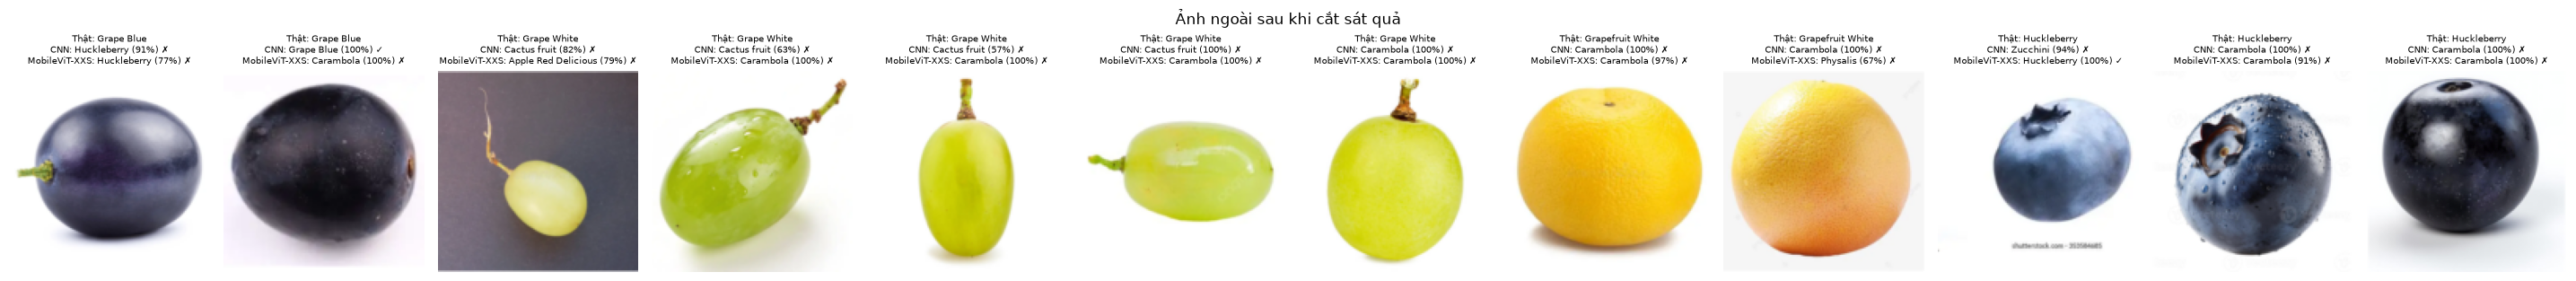

In [13]:
# ===== THÍ NGHIỆM C2: cắt sát quả trước khi đưa vào model (KHÔNG cần train lại) =====
# Ảnh Fruits-360: quả chiếm gần TRỌN khung hình. Ảnh tải trên mạng: quả nhỏ, nhiều viền trắng.
# Ô này tự tìm vùng có quả, cắt sát rồi mới resize -> giống cách chụp của dataset.
def load_for_model_crop(path, thr=235, margin=0.04):
    a = np.asarray(Image.open(path).convert("RGB"))
    mask = a.min(axis=-1) < thr                       # pixel không phải nền trắng
    if mask.sum() > 0.01 * mask.size:                 # tìm thấy quả thì cắt sát, không thì giữ nguyên
        ys, xs = np.where(mask)
        y0, y1, x0, x1 = ys.min(), ys.max(), xs.min(), xs.max()
        my, mx = int((y1 - y0) * margin), int((x1 - x0) * margin)
        a = a[max(0, y0 - my): y1 + my + 1, max(0, x0 - mx): x1 + mx + 1]
    img = Image.fromarray(a)
    side = max(img.size)
    canvas = Image.new("RGB", (side, side), (255, 255, 255))
    canvas.paste(img, ((side - img.size[0]) // 2, (side - img.size[1]) // 2))
    return np.asarray(canvas.resize(IMG_SIZE, Image.BILINEAR), dtype="float32")

X_ext_crop = np.stack([load_for_model_crop(p) for p in ext_paths])
rows = []
for name, model in trained.items():
    pred_old = model.predict(np.stack([load_for_model(p) for p in ext_paths]), verbose=0).argmax(1)
    pred_new = model.predict(X_ext_crop, verbose=0).argmax(1)
    print(f"{name}: không cắt {np.mean(pred_old == ext_labels)*100:.1f}%  →  cắt sát {np.mean(pred_new == ext_labels)*100:.1f}%")
    top_old = pd.Series([class_names[k] for k in pred_old]).value_counts().head(3).to_dict()
    print(f"   Lớp bị đoán nhiều nhất khi KHÔNG cắt: {top_old}")
    for c in sorted(set(ext_labels)):
        m = ext_labels == c
        rows.append({"Mô hình": name, "Lớp": class_names[c], "Số ảnh": int(m.sum()),
                     "Đúng (không cắt)": int((pred_old[m] == c).sum()),
                     "Đúng (cắt sát)": int((pred_new[m] == c).sum())})
display(pd.DataFrame(rows).set_index(["Lớp", "Mô hình"]).sort_index())

n_show = min(len(ext_paths), 12)
fig, axes = plt.subplots(1, n_show, figsize=(2.4 * n_show, 3.4), squeeze=False)
for ax, i in zip(axes[0], range(n_show)):
    ax.imshow(X_ext_crop[i].astype("uint8")); ax.axis("off")
    lines = [f"Thật: {class_names[ext_labels[i]]}"]
    for name, model in trained.items():
        p = model.predict(X_ext_crop[i:i + 1], verbose=0)[0]; k = p.argmax()
        lines.append(f"{name.split()[0]}: {class_names[k]} ({p[k]*100:.0f}%)" + (" ✓" if k == ext_labels[i] else " ✗"))
    ax.set_title("\n".join(lines), fontsize=7)
plt.suptitle("Ảnh ngoài sau khi cắt sát quả"); plt.tight_layout(); savefig("10b_external_crop.png"); plt.show()

## 10. Grad-CAM — mô hình nhìn vào đâu?

**Grad-CAM** tô màu vùng ảnh ảnh hưởng nhiều nhất tới quyết định của mô hình (đỏ = quan trọng). Cách tính: lấy đạo hàm của điểm số lớp được dự đoán theo feature map của **lớp conv cuối cùng**, lấy trung bình đạo hàm làm trọng số cho từng kênh rồi cộng có trọng số các kênh lại.

So sánh trên **ảnh gốc** và **ảnh đã đổi nền**: mô hình tốt nên tập trung vào **quả**, không phải nền.

> Feature map cuối của CNN tự xây là 28×28, còn của MobileViT chỉ 4×4 (ảnh đã bị giảm 32 lần) nên bản đồ nhiệt của MobileViT **thô hơn** — đây là khác biệt do kiến trúc, không phải lỗi.

Đã lưu hình: /home/tranduydang/fruit-cnn-project/results/11_gradcam.png


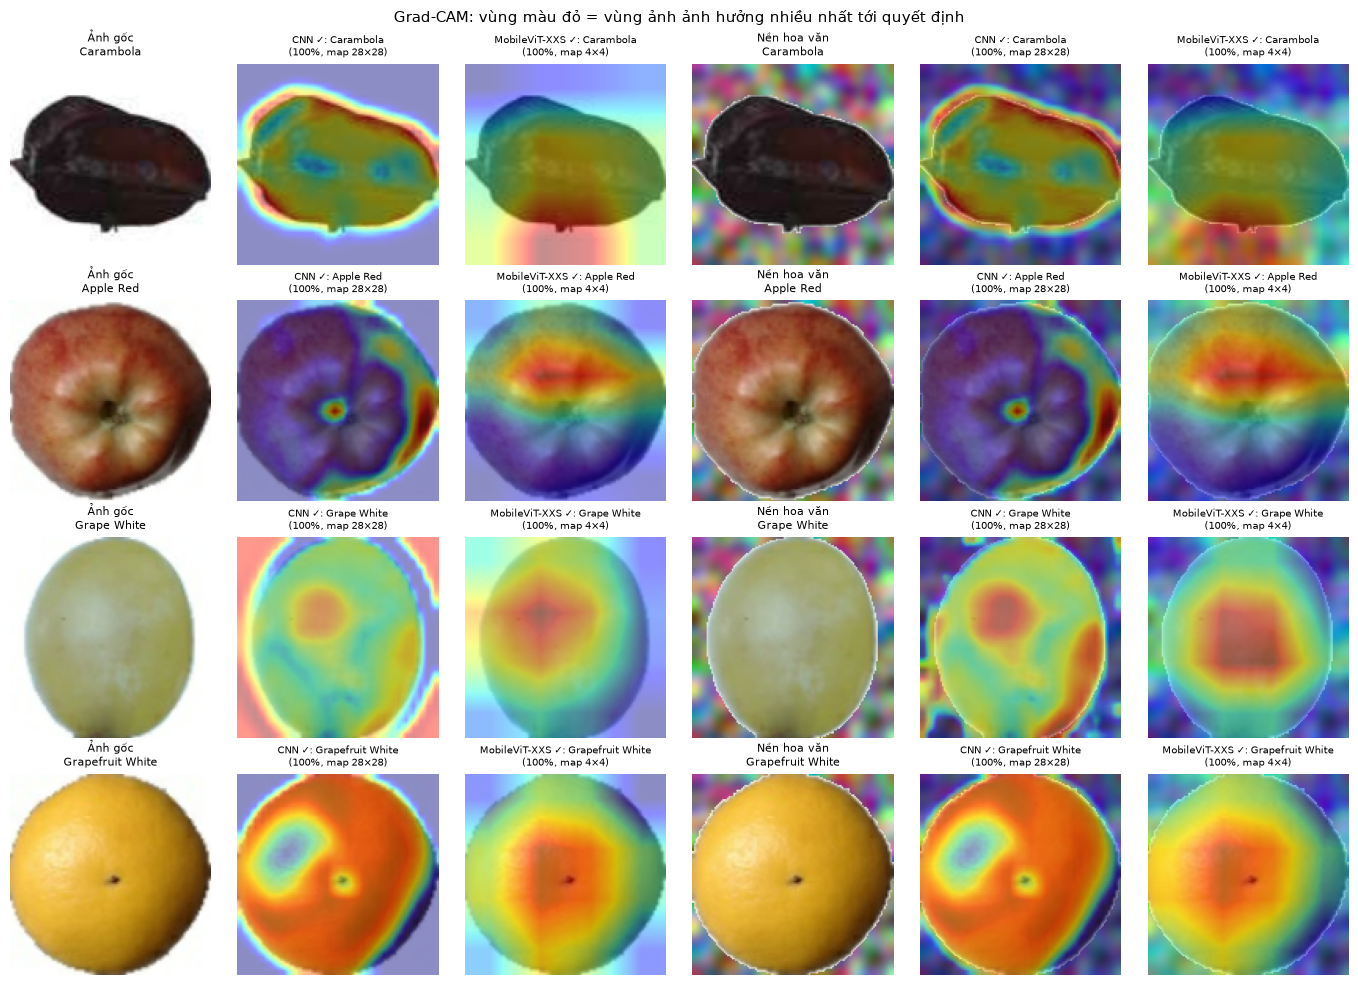

In [21]:
CAM_LAYERS = {CNN_NAME: "conv3", MVIT_NAME: "head_conv1x1_swish"}   # lớp conv cuối cùng của mỗi mạng

def grad_cam(model, layer_name, img):
    """Grad-CAM: lấy gradient của điểm số (logit) lớp được dự đoán theo feature map của lớp conv cuối,
    lấy trung bình gradient làm trọng số cho từng kênh -> bản đồ nhiệt 'vùng quyết định'."""
    dense = model.get_layer("predictions")
    grad_model = keras.Model(model.input, [model.get_layer(layer_name).output, dense.input, model.output])
    x = tf.convert_to_tensor(img[None], tf.float32)
    with tf.GradientTape() as tape:
        fmap, feat, preds = grad_model(x, training=False)
        k = int(tf.argmax(preds[0]))
        # dùng LOGIT (điểm trước softmax): nếu dùng xác suất, khi model tự tin ~100% thì gradient ≈ 0 -> bản đồ trống
        score = tf.matmul(feat, dense.kernel)[:, k] + dense.bias[k]
    grads = tape.gradient(score, fmap)
    weights = tf.reduce_mean(grads, axis=(1, 2))                       # [1, C]
    cam = tf.nn.relu(tf.reduce_sum(fmap[0] * weights[0], axis=-1))     # [h, w]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., None], IMG_SIZE)[..., 0].numpy()
    return cam, k, float(preds[0, k]), tuple(fmap.shape[1:3])

# Chọn 4 ảnh test thuộc 4 lớp khác nhau, xem trên ảnh gốc và ảnh đã đổi nền
rng = np.random.default_rng(SEED)
picked_classes = rng.choice(num_classes, size=min(4, num_classes), replace=False)
idxs = [int(rng.choice(np.where(test_labels == c)[0])) for c in picked_classes]
variants = {"Ảnh gốc": lambda x, m: x,
            "Nền hoa văn": lambda x, m: np.clip(c_bg_texture(x, m, np.random.default_rng(0)), 0, 255)}

cols = len(variants) * (1 + len(trained))
fig, axes = plt.subplots(len(idxs), cols, figsize=(2.3 * cols, 2.5 * len(idxs)), squeeze=False)
for r, i in enumerate(idxs):
    col = 0
    for vname, vfn in variants.items():
        img = vfn(X_test[i:i + 1].astype("float32"), BG_MASKS[i:i + 1])[0]
        axes[r, col].imshow(img.astype("uint8")); axes[r, col].axis("off")
        axes[r, col].set_title(f"{vname}\n{class_names[test_labels[i]]}", fontsize=8); col += 1
        for name, model in trained.items():
            cam, k, p, hw = grad_cam(model, CAM_LAYERS[name], img)
            axes[r, col].imshow(img.astype("uint8")); axes[r, col].imshow(cam, cmap="jet", alpha=0.45)
            ok = "✓" if k == test_labels[i] else "✗"
            axes[r, col].set_title(f"{name.split()[0]} {ok}: {class_names[k]}\n({p*100:.0f}%, map {hw[0]}×{hw[1]})",
                                   fontsize=7, color="black" if k == test_labels[i] else "#c0392b")
            axes[r, col].axis("off"); col += 1
plt.suptitle("Grad-CAM: vùng màu đỏ = vùng ảnh ảnh hưởng nhiều nhất tới quyết định", fontsize=11)
plt.tight_layout(); savefig("11_gradcam.png"); plt.show()

## 11. Tổng kết

Ô dưới đây gom mọi số liệu vào **1 bảng** và **tự sinh nhận xét từ chính số liệu đo được** (không viết sẵn kết luận), đồng thời lưu `results/results.json`, `results/summary_table.csv` và toàn bộ hình vào thư mục `results/` để đưa vào slide/báo cáo.

In [12]:
C, M = CNN_NAME, MVIT_NAME
noise_keys = [k for k in CORRUPTIONS if k != "Gốc (không đổi)"]
bg_keys = [k for k in CORRUPTIONS if k.startswith("Nền")]
rows = {
    "Accuracy Test (%)":                 {n: eval_results[n]["acc"] * 100 for n in trained},
    "Macro-F1 Test (%)":                 {n: eval_results[n]["macro_f1"] * 100 for n in trained},
    "Số tham số (triệu)":                {n: bench[n]["Số tham số (triệu)"] for n in trained},
    "Dung lượng float32 (MB)":          {n: bench[n]["Dung lượng float32 (MB)"] for n in trained},
    "GFLOPs / ảnh":                      {n: bench[n]["GFLOPs / ảnh"] for n in trained},
    "Thời gian train (s/epoch)":         {n: bench[n]["Thời gian train (s/epoch)"] for n in trained},
    "CPU — 1 ảnh (ms)":                  {n: bench[n]["CPU — 1 ảnh (ms)"] for n in trained},
    "Acc. TB khi ảnh bị biến đổi (%)":   {n: np.mean([rob[n][k] for k in noise_keys]) * 100 for n in trained},
    "Acc. TB khi đổi nền (%)":           {n: np.mean([rob[n][k] for k in bg_keys]) * 100 for n in trained},
}
if gpus:
    rows["GPU — 1 ảnh (ms)"] = {n: bench[n]["GPU — 1 ảnh (ms)"] for n in trained}
if RUN_DATA_EFFICIENCY:
    smallest = eff_df["Tỷ lệ dữ liệu"].min()
    s = eff_df[eff_df["Tỷ lệ dữ liệu"] == smallest].groupby("Mô hình")["Accuracy"].mean()
    rows[f"Acc. khi chỉ có {smallest:.0%} dữ liệu (%)"] = {n: s[n] * 100 for n in trained}
if ext_acc:
    rows["Acc. ảnh ngoài đời thật (%)"] = {n: ext_acc[n] * 100 for n in trained}
final_df = pd.DataFrame(rows).T[[C, M]]
display(final_df.round(3))

# ---------- Nhận xét tự động, sinh ra từ CHÍNH số liệu vừa đo ----------
def better(metric, higher_is_better=True):
    a, b = final_df.loc[metric, C], final_df.loc[metric, M]
    if np.isclose(a, b, rtol=0.02):
        return "ngang nhau"
    return (M if (b > a) == higher_is_better else C)

notes = []
acc_c, acc_m = final_df.loc["Accuracy Test (%)", C], final_df.loc["Accuracy Test (%)", M]
notes.append(f"**Độ chính xác trên Test sạch:** {C} {acc_c:.2f}% — {M} {acc_m:.2f}% (chênh {abs(acc_m-acc_c):.2f} điểm). "
             + ("Chênh lệch **không có ý nghĩa thống kê** — chưa đủ bằng chứng để nói mô hình nào chính xác hơn" if mcnemar_p >= 0.05 else "Chênh lệch **có ý nghĩa thống kê**")
             + f" (McNemar p = {mcnemar_p:.3g}).")
if min(acc_c, acc_m) > 97:
    notes[-1] += " Cả 2 đều > 97%: bộ Fruits-360 sạch quá dễ nên accuracy gần như bão hoà, cần các tiêu chí khác để phân biệt."
pr = final_df.loc["Số tham số (triệu)", C] / final_df.loc["Số tham số (triệu)", M]
notes.append(f"**Kích thước:** {M} có {final_df.loc['Số tham số (triệu)', M]:.2f}M tham số, "
             + (f"ít hơn {pr:.1f} lần" if pr > 1 else f"nhiều hơn {1/pr:.1f} lần")
             + f" so với {C} ({final_df.loc['Số tham số (triệu)', C]:.2f}M — phần lớn nằm ở lớp Dense sau Flatten).")
fr = final_df.loc["GFLOPs / ảnh", C] / final_df.loc["GFLOPs / ảnh", M]
notes.append(f"**Số phép tính:** {C} {final_df.loc['GFLOPs / ảnh', C]:.3f} GFLOPs/ảnh, {M} "
             f"{final_df.loc['GFLOPs / ảnh', M]:.3f} GFLOPs/ảnh ⇒ {M} "
             + (f"ít hơn {fr:.1f} lần." if fr > 1 else f"nhiều hơn {1/fr:.1f} lần."))
lat_key = "GPU — 1 ảnh (ms)" if gpus else "CPU — 1 ảnh (ms)"
faster = better(lat_key, higher_is_better=False)
notes.append(f"**Tốc độ suy luận ({lat_key}):** {C} {final_df.loc[lat_key, C]:.2f} ms — {M} {final_df.loc[lat_key, M]:.2f} ms ⇒ "
             + ("hai mô hình ngang nhau." if faster == "ngang nhau" else f"{faster} nhanh hơn.")
             + (" Ít FLOPs hơn nhưng không nhanh hơn ⇒ tốc độ thực tế còn phụ thuộc số lớp, phép reshape/attention, "
                "chứ không chỉ số phép nhân." if (fr > 1 and faster == C) else ""))
notes.append(f"**Thời gian huấn luyện:** {C} {final_df.loc['Thời gian train (s/epoch)', C]:.1f} s/epoch — "
             f"{M} {final_df.loc['Thời gian train (s/epoch)', M]:.1f} s/epoch.")
for key in ["Acc. TB khi ảnh bị biến đổi (%)", "Acc. TB khi đổi nền (%)"]:
    w = better(key)
    notes.append(f"**{key.replace(' (%)', '')}:** {C} {final_df.loc[key, C]:.1f}% — {M} {final_df.loc[key, M]:.1f}% ⇒ "
                 + ("tương đương." if w == "ngang nhau" else f"{w} bền hơn."))
worst = {n: min(noise_keys, key=lambda k: rob[n][k]) for n in trained}
notes.append("**Biến đổi gây hại nhiều nhất:** " + "; ".join(
    f"{n}: '{worst[n]}' ({rob[n][worst[n]]*100:.1f}%)" for n in trained) + ".")
if RUN_DATA_EFFICIENCY:
    key = [k for k in final_df.index if k.startswith("Acc. khi chỉ có")][0]
    w = better(key)
    notes.append(f"**{key.replace(' (%)', '')}:** {C} {final_df.loc[key, C]:.1f}% — {M} {final_df.loc[key, M]:.1f}% ⇒ "
                 + ("tương đương." if w == "ngang nhau" else f"{w} học tốt hơn khi ít dữ liệu."))
if ext_acc:
    notes.append(f"**Ảnh ngoài đời thật:** {C} {ext_acc[C]*100:.1f}% — {M} {ext_acc[M]*100:.1f}% "
                 f"(trên {len(ext_paths)} ảnh — ít ảnh nên chỉ mang tính tham khảo).")
display(Markdown("### Nhận xét rút ra từ số liệu\n" + "\n".join(f"{i+1}. {t}" for i, t in enumerate(notes))))

# Lưu toàn bộ số liệu để dùng cho báo cáo / slide
results_json = {
    "class_names": class_names, "img_size": list(IMG_SIZE), "mobilevit_variant": MOBILEVIT_VARIANT,
    "summary": final_df.round(4).to_dict(), "mcnemar": {"cnn_only_correct": mc_b, "mvit_only_correct": mc_c, "p_value": mcnemar_p},
    "robustness": {n: {k: round(v * 100, 2) for k, v in rob[n].items()} for n in trained},
    "data_efficiency": eff_df.to_dict(orient="records"), "train_info": train_info,
    "notes": notes,
}
with open(os.path.join(RESULTS_DIR, "results.json"), "w", encoding="utf-8") as f:
    json.dump(results_json, f, ensure_ascii=False, indent=2, default=float)
final_df.to_csv(os.path.join(RESULTS_DIR, "summary_table.csv"), encoding="utf-8-sig")
print("Đã lưu:", os.path.join(RESULTS_DIR, "results.json"), "và summary_table.csv")
print("Các hình cho slide nằm trong:", RESULTS_DIR, "→", sorted(f for f in os.listdir(RESULTS_DIR) if f.endswith(".png")))

,CNN tự xây,MobileViT-XXS
Accuracy Test (%),100.000,100.000
Macro-F1 Test (%),100.000,100.000
Số tham số (triệu),3.307,0.960
Dung lượng float32 (MB),13.226,3.840
GFLOPs / ảnh,0.287,0.174
Thời gian train (s/epoch),4.168,8.155
CPU — 1 ảnh (ms),347.130,135.855
Acc. TB khi ảnh bị biến đổi (%),84.142,70.616
Acc. TB khi đổi nền (%),95.335,78.970
GPU — 1 ảnh (ms),1.370,12.485


### Nhận xét rút ra từ số liệu
1. **Độ chính xác trên Test sạch:** CNN tự xây 100.00% — MobileViT-XXS 100.00% (chênh 0.00 điểm). Chênh lệch **không có ý nghĩa thống kê** — chưa đủ bằng chứng để nói mô hình nào chính xác hơn (McNemar p = 1). Cả 2 đều > 97%: bộ Fruits-360 sạch quá dễ nên accuracy gần như bão hoà, cần các tiêu chí khác để phân biệt.
2. **Kích thước:** MobileViT-XXS có 0.96M tham số, ít hơn 3.4 lần so với CNN tự xây (3.31M — phần lớn nằm ở lớp Dense sau Flatten).
3. **Số phép tính:** CNN tự xây 0.287 GFLOPs/ảnh, MobileViT-XXS 0.174 GFLOPs/ảnh ⇒ MobileViT-XXS ít hơn 1.6 lần.
4. **Tốc độ suy luận (GPU — 1 ảnh (ms)):** CNN tự xây 1.37 ms — MobileViT-XXS 12.48 ms ⇒ CNN tự xây nhanh hơn. Ít FLOPs hơn nhưng không nhanh hơn ⇒ tốc độ thực tế còn phụ thuộc số lớp, phép reshape/attention, chứ không chỉ số phép nhân.
5. **Thời gian huấn luyện:** CNN tự xây 4.2 s/epoch — MobileViT-XXS 8.2 s/epoch.
6. **Acc. TB khi ảnh bị biến đổi:** CNN tự xây 84.1% — MobileViT-XXS 70.6% ⇒ CNN tự xây bền hơn.
7. **Acc. TB khi đổi nền:** CNN tự xây 95.3% — MobileViT-XXS 79.0% ⇒ CNN tự xây bền hơn.
8. **Biến đổi gây hại nhiều nhất:** CNN tự xây: 'Giảm tương phản' (25.8%); MobileViT-XXS: 'Tối đi 50%' (21.8%).
9. **Acc. khi chỉ có 2% dữ liệu:** CNN tự xây 96.2% — MobileViT-XXS 95.9% ⇒ tương đương.
10. **Ảnh ngoài đời thật:** CNN tự xây 25.0% — MobileViT-XXS 25.0% (trên 24 ảnh — ít ảnh nên chỉ mang tính tham khảo).

Đã lưu: /home/tranduydang/fruit-cnn-project/results/results.json và summary_table.csv
Các hình cho slide nằm trong: /home/tranduydang/fruit-cnn-project/results → ['01_classes.png', '02_mobilevit_block.png', '03_unfold.png', '04_learning_curves.png', '05_confusion_matrices.png', '06_efficiency.png', '07_data_efficiency.png', '08_corruption_examples.png', '09_robustness.png', '10_external.png', '11_gradcam.png']


### Gợi ý cách trình bày kết luận (điền theo số liệu ở trên)
1. **Trên dữ liệu sạch**, cả 2 mô hình đều gần như tuyệt đối → Fruits-360 (nền trắng, điều kiện chụp chuẩn) **không đủ khó** để phân biệt 2 kiến trúc chỉ bằng accuracy.
2. **Về hiệu quả**, so sánh số tham số, FLOPs, dung lượng và tốc độ ở mục 6: MobileViT dùng GAP thay cho Flatten + Dense nên **rất nhẹ**; nhưng **ít phép tính chưa chắc đã chạy nhanh hơn** — nêu đúng con số đo được.
3. **Về độ bền và khả năng tổng quát** (mục 7, 8, 9): đây là phần quyết định "mô hình nào tốt hơn ngoài đời thật". Nêu biến đổi nào làm mỗi mô hình tụt nhiều nhất, đặc biệt là **đổi nền**.
4. **Hạn chế & hướng phát triển:** dataset quá "sạch"; chưa dùng trọng số pretrained cho MobileViT (để so sánh công bằng kiến trúc); có thể thử augmentation mạnh hơn (đổi nền ngẫu nhiên khi train), fine-tune MobileViT pretrained, hoặc đưa mô hình lên điện thoại (TFLite) để đo tốc độ thật.

📄 Kịch bản thuyết trình chi tiết và các câu hỏi thầy cô có thể hỏi: xem file **`HUONG_DAN_THUYET_TRINH_MobileViT_vs_CNN.md`** đi kèm.